# Day 4.5 analysis

In [1]:
library(rhdf5)

Warning message:
“package ‘rhdf5’ was built under R version 4.2.3”


In [2]:
here::i_am("Manuscript/day_253.ipynb")

source(here::here("settings.R"))
source(here::here("utils.R"))

suppressPackageStartupMessages(library(scran))
suppressPackageStartupMessages(library(scater))
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(dplyr))
suppressPackageStartupMessages(library(ArchR))

BPPARAM <- BiocParallel::bpparam()
BPPARAM$workers = 21

# Multi core using future - built in to seurat
plan("multicore", workers = 16)
options(future.globals.maxSize = 50 * 1024 ^ 3) # for 50 Gb RAM

here() starts at /rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/code


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,--,__,=##,__   ///
        ,    __==    ___,-,__,--'#'  ==='      `-'    | ##,-/
        -,____,---'       \\####\\________________,--\\_##,/
        

In [3]:
args = list()
# UMAP
args$MOFA_factors = file.path(io$basedir, 'results/rna_atac/dimensionality_reduction/mofa/MOFA_factors.txt.gz')
args$MOFA_umap = file.path(io$basedir, 'results/rna_atac/dimensionality_reduction/mofa/MOFA_umap.txt.gz')

# RNA_sce
args$rna_sce = file.path(io$basedir, 'processed/rna/SingleCellExperiment.rds')

# Archr
args$archr_directory = file.path(io$basedir, 'processed/atac/archR')

# Mapping Luke
#args$integrated_object = '/rds/project/rds-SDzz0CATGms/users/ltgh2/projects/01_Eomes_invitro_HE_multiome/processed/rna/seurat_objects/all_anchors_20_rPCA.rds'

# outdir
args$outdir = file.path(io$basedir, 'results/manuscript/day_45_v2/')
dir.create(args$outdir, showWarnings = F, recursive = T)

# Metadata
args$metadata = file.path(io$basedir, 'results/rna_atac/combined_metadata.txt.gz')

# Mapping metadata
args$mapping = file.path(io$basedir, 'results/rna/mapping/sample_metadata_after_mapping.txt.gz')

In [4]:
args$MOFA_factors

[1] "/rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/results/rna_atac/dimensionality_reduction/mofa/MOFA_factors.txt.gz"

In [5]:
# Load meta
meta = fread(args$metadata)

In [66]:
table(meta$genotype, meta$pass_atacQC, meta$pass_rnaQC)

, ,  = TRUE

          
           TRUE
  Eomes KD 7242
  WT       4677


In [64]:
head(meta)

cell,orig.ident,nCount_RNA,nFeature_RNA,barcode,sample,mitochondrial_percent_RNA,ribosomal_percent_RNA,alias,day,⋯,PromoterRatio_atac,NucleosomeRatio_atac,nFrags_atac,BlacklistRatio_atac,pass_atacQC,RNA_snn_res.0.9,seurat_clusters,celltype_manual,umap1,umap2
<chr>,<chr>,<int>,<int>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,⋯,<dbl>,<dbl>,<int>,<dbl>,<lgl>,<int>,<int>,<chr>,<dbl>,<dbl>
RBG43477#AAACAGCCAACACCTA-1,SeuratProject,3455,2075,AAACAGCCAACACCTA-1,RBG43477,0.64,6.77,D4.5_KO_rep1,D4.5,⋯,0.36,0.83,7041,0.03,TRUE,2,2,Ectoderm,-4.6088601,3.6075785
RBG43477#AAACAGCCAATGAAGC-1,SeuratProject,6411,2526,AAACAGCCAATGAAGC-1,RBG43477,17.80,4.93,D4.5_KO_rep1,D4.5,⋯,0.20,1.53,23527,0.02,TRUE,3,3,Pre-somitic mesoderm,-0.6046364,-2.7638063
RBG43477#AAACAGCCAGCATTAT-1,SeuratProject,8305,3231,AAACAGCCAGCATTAT-1,RBG43477,14.55,6.63,D4.5_KO_rep1,D4.5,⋯,0.21,1.19,20992,0.02,TRUE,8,8,Paraxial mesoderm,3.4480044,-5.9670613
RBG43477#AAACAGCCAGGAAGCC-1,SeuratProject,7102,3087,AAACAGCCAGGAAGCC-1,RBG43477,14.76,5.46,D4.5_KO_rep1,D4.5,⋯,0.22,1.19,23204,0.02,TRUE,2,2,Ectoderm,-4.5962587,3.4620202
RBG43477#AAACAGCCATGGAGGC-1,SeuratProject,4717,2399,AAACAGCCATGGAGGC-1,RBG43477,14.20,5.41,D4.5_KO_rep1,D4.5,⋯,0.21,1.77,13001,0.02,TRUE,0,0,Pre-somitic mesoderm,0.1103073,0.7652224
RBG43477#AAACATGCAAGTAAGC-1,SeuratProject,4821,2342,AAACATGCAAGTAAGC-1,RBG43477,17.55,4.46,D4.5_KO_rep1,D4.5,⋯,0.20,1.41,18457,0.02,TRUE,3,3,Pre-somitic mesoderm,-0.9875219,-3.4120886


## RNA

In [6]:
# load sce
rna.sce <- load_SingleCellExperiment(args$rna_sce, normalise = TRUE, cells = meta$cell)
colData(rna.sce) = meta %>% as.data.frame() %>% tibble::column_to_rownames('cell') %>% DataFrame()

# Convert to Seurat
seurat = as.Seurat(rna.sce)

# Cell Type annotation

In [7]:
set.seed(1234)

In [8]:
factors = fread(args$MOFA_factors)[match(meta$cell, cell)] %>%
    .[meta$day == 'D4.5']

In [9]:
d45_umap = uwot::umap(factors[,-1], n_neighbors = 25, min_dist = 0.2)

In [10]:
d45_umap = as.data.table(d45_umap) %>%
    setnames(c('umap1', 'umap2'))

In [11]:
# load sce
d45_rna.sce = rna.sce[,meta[day == 'D4.5', cell]]

# Convert to Seurat
seurat = as.Seurat(d45_rna.sce)

In [12]:
summary(colnames(seurat) == factors$cell)

   Mode    TRUE 
logical   11919 

In [13]:
# Prepare mofa umap
factors.mtx = factors %>% 
    as.data.frame(.) %>% 
    tibble::column_to_rownames('cell') %>%
    as.matrix()
seurat[["mofa"]] <- CreateDimReducObject(embeddings = factors.mtx, key = "mofa_", assay = DefaultAssay(seurat))

In [14]:
d45_umap.mtx = d45_umap %>% 
    .[,cell := meta[day == 'D4.5', cell]] %>% 
    as.data.frame(.) %>% 
    tibble::column_to_rownames('cell') %>%
    as.matrix()

seurat[["umap"]] <- CreateDimReducObject(embeddings = d45_umap.mtx, key = "umap_", assay = DefaultAssay(seurat))

In [15]:
seurat <- FindNeighbors(seurat, dims = 1:17, reduction = 'mofa')
seurat <- FindClusters(seurat, resolution = 0.9)

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 11919
Number of edges: 401676

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8392
Number of communities: 14
Elapsed time: 1 seconds


Warning message:
“UNRELIABLE VALUE: One of the ‘future.apply’ iterations (‘future_lapply-1’) unexpectedly generated random numbers without declaring so. There is a risk that those random numbers are not statistically sound and the overall results might be invalid. To fix this, specify 'future.seed=TRUE'. This ensures that proper, parallel-safe random numbers are produced via the L'Ecuyer-CMRG method. To disable this check, use 'future.seed = NULL', or set option 'future.rng.onMisuse' to "ignore".”


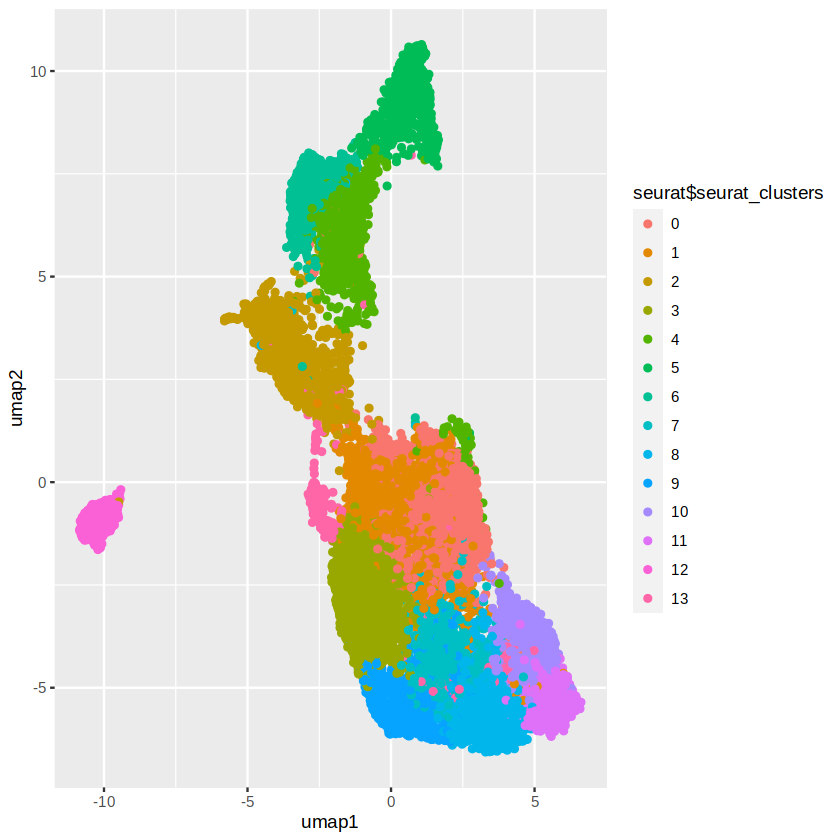

In [16]:
ggplot(d45_umap, aes(umap1, umap2, color = seurat$seurat_clusters)) + geom_point()

In [17]:
Idents(seurat) =  seurat$seurat_clusters

In [18]:
all.genes <- rownames(seurat)
seurat = ScaleData(seurat, features = all.genes)

Centering and scaling data matrix



In [19]:
# find markers for every cluster compared to all remaining cells, report only the positive
# ones
markers <- FindAllMarkers(seurat, only.pos = TRUE)
markers %>%
    group_by(cluster) %>%
    # dplyr::filter(avg_log2FC > 1) %>%
    slice_head(n = 30) %>%
    ungroup() -> top30


Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8

Calculating cluster 9

Calculating cluster 10

Calculating cluster 11

Calculating cluster 12

Calculating cluster 13



In [20]:
lapply(0:13, function(i){
  sprintf('cluster %s: %s', i, paste(as.data.table(markers)[cluster == i, ]$gene %>% head(15), collapse = ', '))
})

[[1]]
[1] "cluster 0: Fat3, Kcnh5, Pdzrn3, Maml3, Gpc6, Limch1, Sulf1, Meis2, Btg2, Plxna2, Arhgap24, Kcnk3, Gad1, Ston2, Vcan"

[[2]]
[1] "cluster 1: Kcnh5, Gpc6, Fat3, Mki67, Pdzrn3, Cenpe, Top2a, Dach1, Meis2, Ski, Cenpf, Diaph3, Arhgap24, Gad1, Kif15"

[[3]]
[1] "cluster 2: Sema3e, Slc2a3, Xkr4, Slc2a1, Nrxn1, Frem2, Bst2, Fgfbp3, Wnt8a, Pla2g7, F2rl1, Lrp2, Dgkb, Pcdh1, Cdh1"

[[4]]
[1] "cluster 3: Grm8, Dll1, Rnf213, Pcdh19, Pld5, Aldh1a2, Smoc1, Tll2, Lef1, Gpc3, Tenm4, Ptprk, Kcnh7, Prtg, Greb1l"

[[5]]
[1] "cluster 4: Pcdh7, Slit2, T, Nav3, Defa30, Trim67, Pde4d, Shh, Lefty1, Pkd1l1, Fgf8, Klhl32, Cthrc1, Cobl, Lypd6b"

[[6]]
[1] "cluster 5: Flt1, Amot, Emb, Nrp1, Trh, 9030622O22Rik, Fgf5, Dkk1, Otx2, Igfbp2, Cacna2d3, Car4, Fzd5, Kit, Cfap299"

[[7]]
[1] "cluster 6: Pkd1l1, Cobl, Slit2, T, Sgcd, Bicc1, 9030622O22Rik, Gpc5, Cthrc1, Frem2, Cldn6, Defa30, Cfc1, Lypd6b, Chrd"

[[8]]
[1] "cluster 7: Pcdh8, Pcsk5, Zfp536, Myocd, Epha4, Lama1, Fbn2, Pax3, Nrp2, Adgrl2, Snap91, Foxp1, Kcnj6, Chst8, Fgfr1"

[[9]]
[1] "cluster 8: Pax3, Uncx, Cdh11, Ebf1, Sorcs3, Col26a1, Col23a1, Fbn2, Kcnc2, Efnb2, Cdh18, Prrx2, Adgrb3, Tcf15, Boc"

[[10]]
[1] "cluster 9: Pcdh8, Myocd, Kcnn3, Lrrtm3, Adgrl2, Snap91, Pcsk5, Epha4, Pax3, Notch1, Pcdh19, Notch2, Rftn2, Lef1, Abca1"

[[11]]
[1] "cluster 10: Col26a1, Col5a1, Acss1, Mir100hg, Cdh11, Col1a1, Loxl1, Runx1, Nav1, Itga9, Creb5, Twist2, Tns1, Parm1, Cacna1c"

[[12]]
[1] "cluster 11: Acss1, Col1a1, Col5a1, Runx1, Col26a1, Mir100hg, Ssc5d, Nav1, Morrbid, Loxl2, Itga9, Creb5, Loxl1, Epha10, Nav2"

[[13]]
[1] "cluster 12: Dnah8, Lima1, Dppa5a, Zfp42, Rnf17, 9330185C12Rik, Pdzrn4, Sox2, Spp1, Tfcp2l1, Abcc4, Zfp980, Zfp981, Jade1, Nr5a2"

[[14]]
[1] "cluster 13: Pygm, Gm15892, Polg2, 2210016F16Rik, Sox11, Rbbp6, Usp3, G630016G05Rik, Cep76, Mapk8, Peli1, Gm49692, Ube2q2, Ninl, Mcmbp"

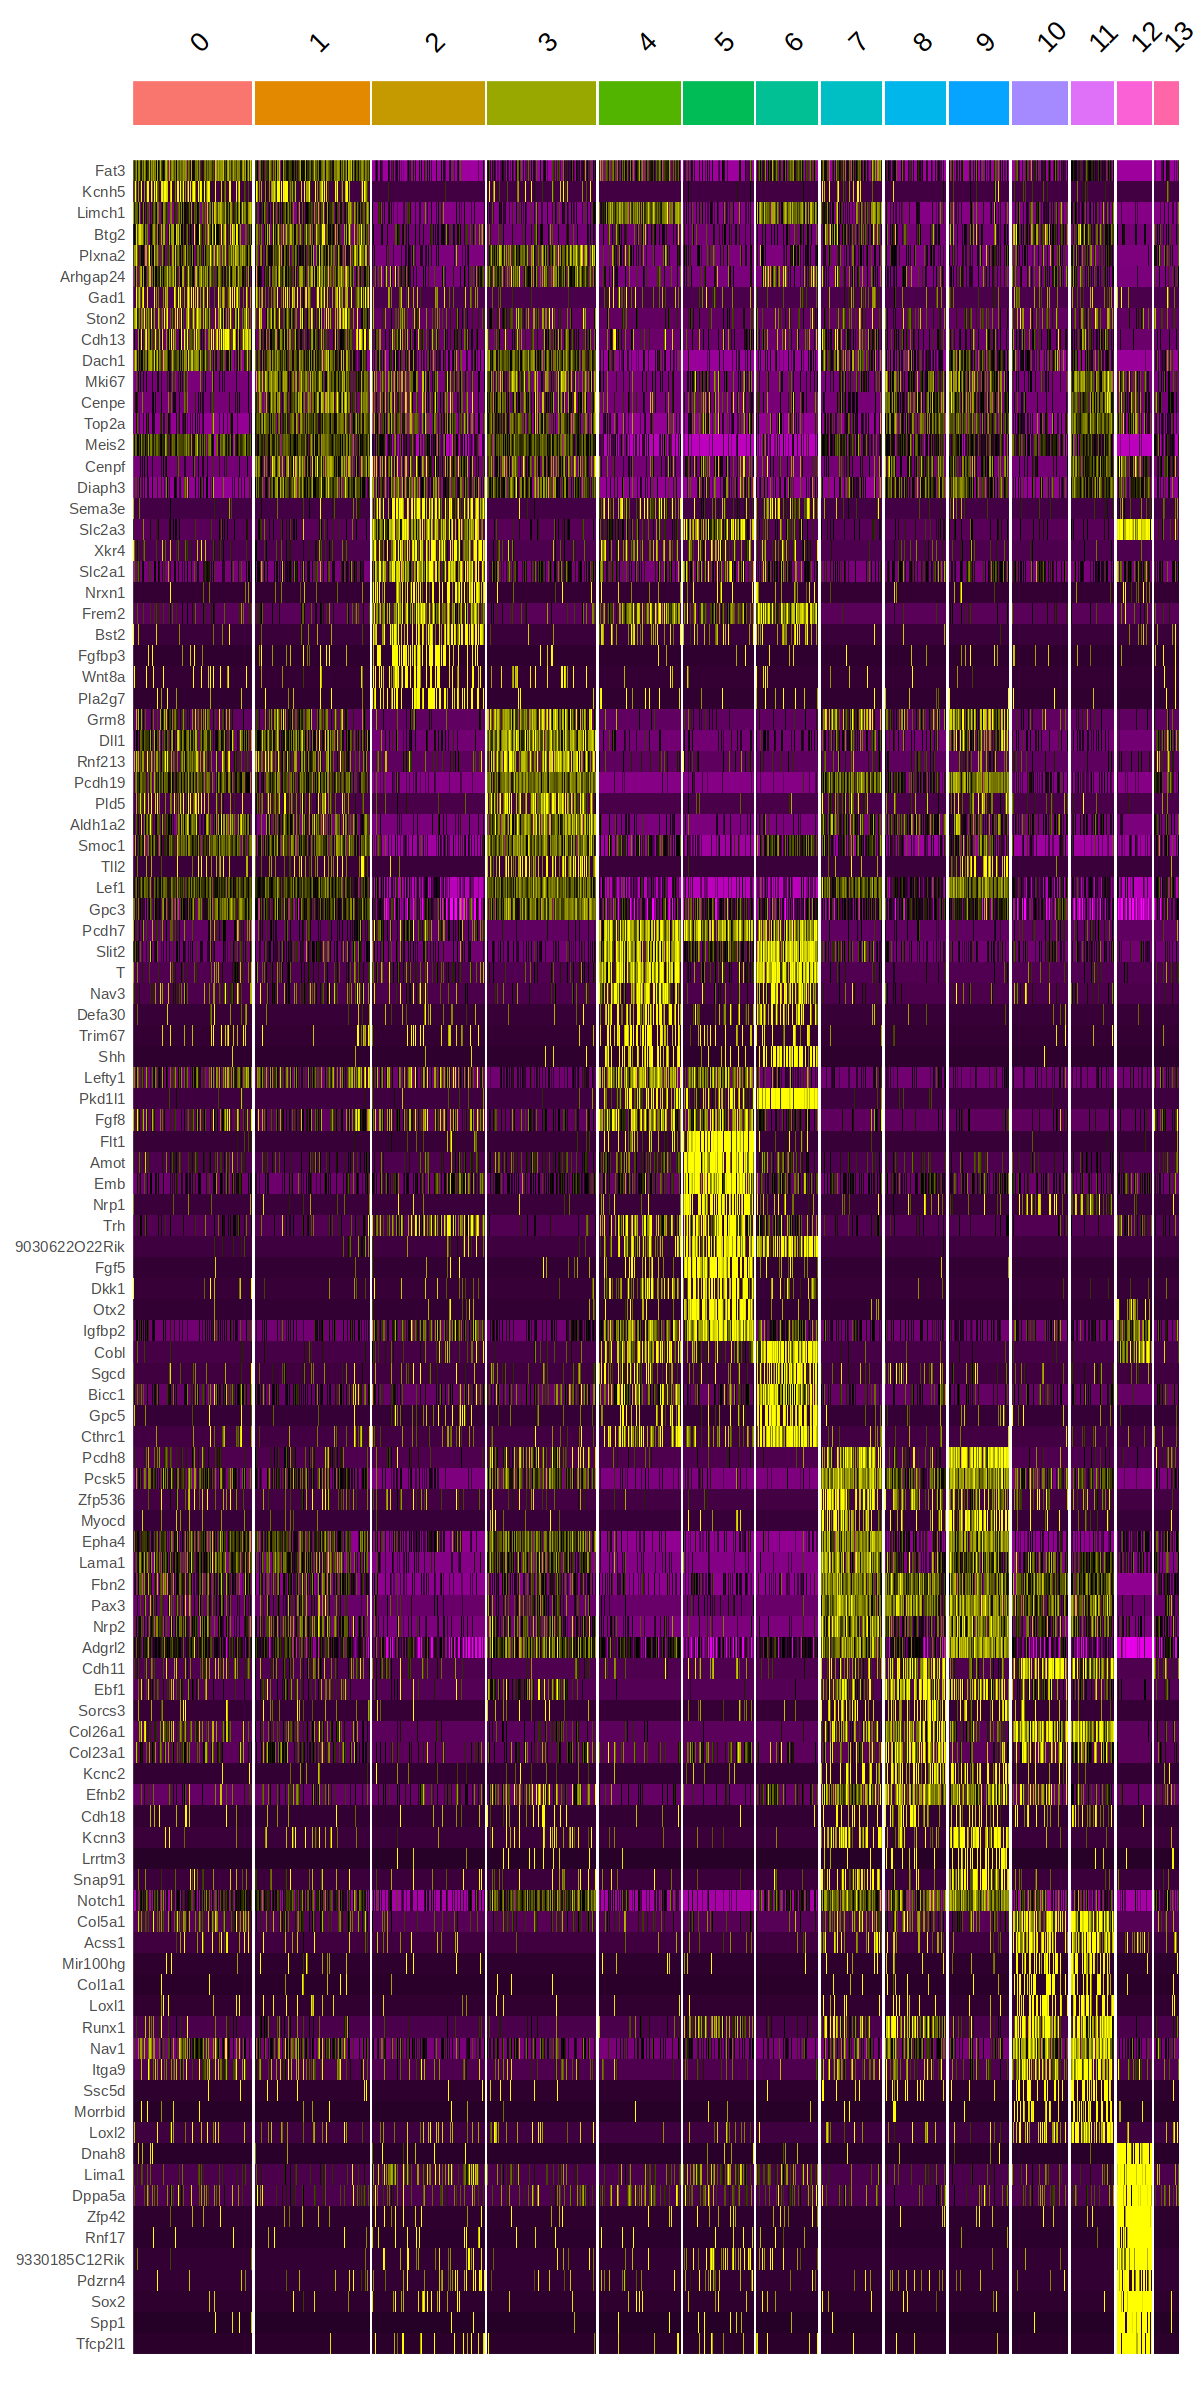

In [21]:
options(repr.plot.width = 10, repr.plot.height = 20)

markers %>%
    group_by(cluster) %>%
    dplyr::filter(avg_log2FC > 0.5) %>%
    slice_head(n = 10) %>%
    ungroup() -> top10
DoHeatmap(seurat, features = top10$gene) + NoLegend()



Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


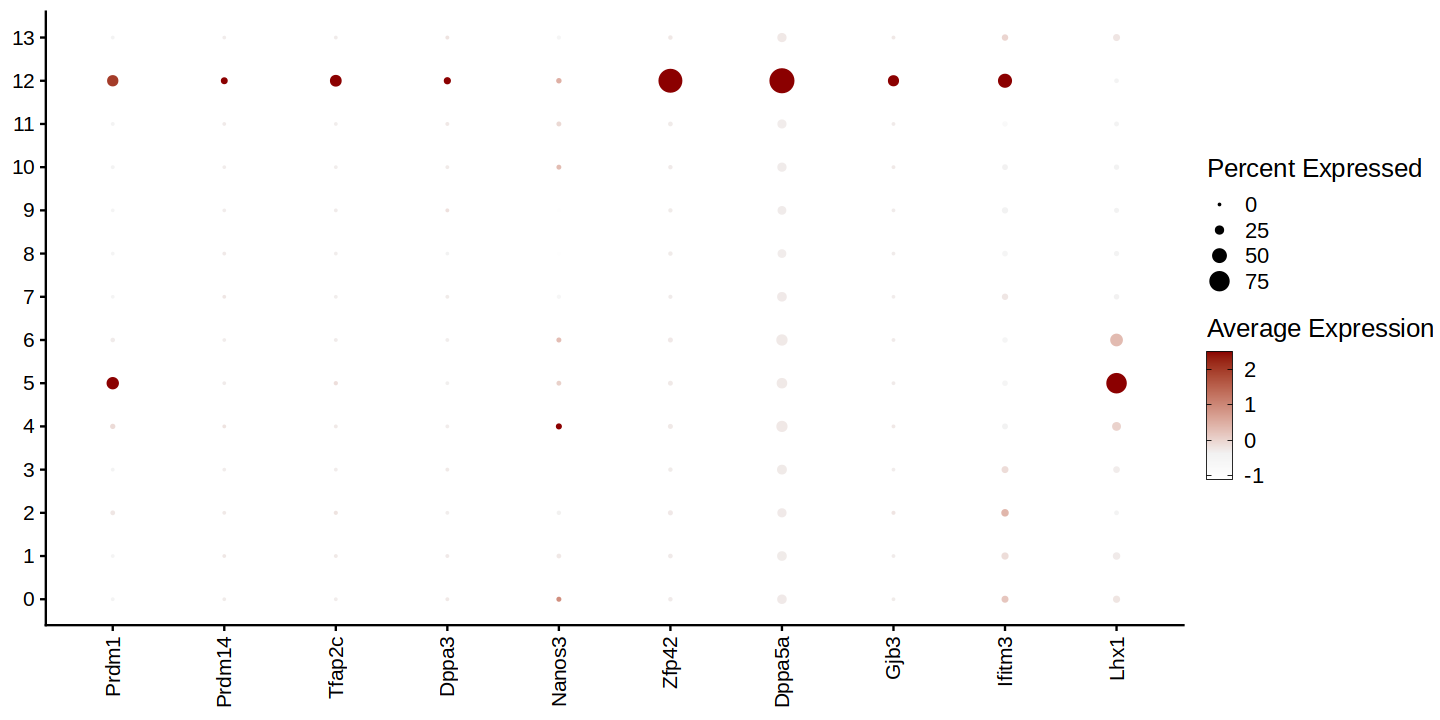

In [22]:
features = c(
    'Prdm1', 'Prdm14', 'Tfap2c', 'Dppa3','Nanos3', 'Zfp42', 'Dppa5a','Gjb3', 'Ifitm3', 'Lhx1'
)

options(repr.plot.width=12, repr.plot.height=6)
p = DotPlot(seurat, features = features) + 
    # scale_color_gradient(low='white', high='darkred', name='Average Expression') + 
    scale_color_gradientn(colours = c('white', 'grey95','darkred'), values = c(0, 0.2,1), name='Average Expression') + 
    guides(color = guide_colourbar(
         # barwidth = 0.5, barheight = 2.5,
        frame.colour = "black", 
        ticks.colour = "black"
    )) + 
    RotatedAxis() +
    ylab('celltype genotype') + xlab('') +
    theme(text=element_text(size=15), 
                         axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5),
                         axis.text.y=element_text(hjust=1),
         axis.title = element_blank())

p

In [23]:
cluster2celltype = c(
    '0' = 'Pre-somitic mesoderm',
    '1' = 'Pre-somitic mesoderm',
    '2' = 'Ectoderm', # Wnt8a, Sema3e, Fgfbp3 == ectoderm!! But also some notochord markers
    '3' = 'Pre-somitic mesoderm', 
    '4' = 'Notochord 1', # 
    '5' = 'DE/Gut',
    '6' = 'Notochord 2', # Chrd, T, Foxa2, Slit2
    '7' = 'Paraxial mesoderm',
    '8' = 'Paraxial mesoderm',
    '9' = 'Paraxial mesoderm',
    '10' = 'Mesenchyme',
    '11' = 'Mesenchyme',
    '12' = 'Pluripotent/PGC',
    '13' = 'Low quality'
)


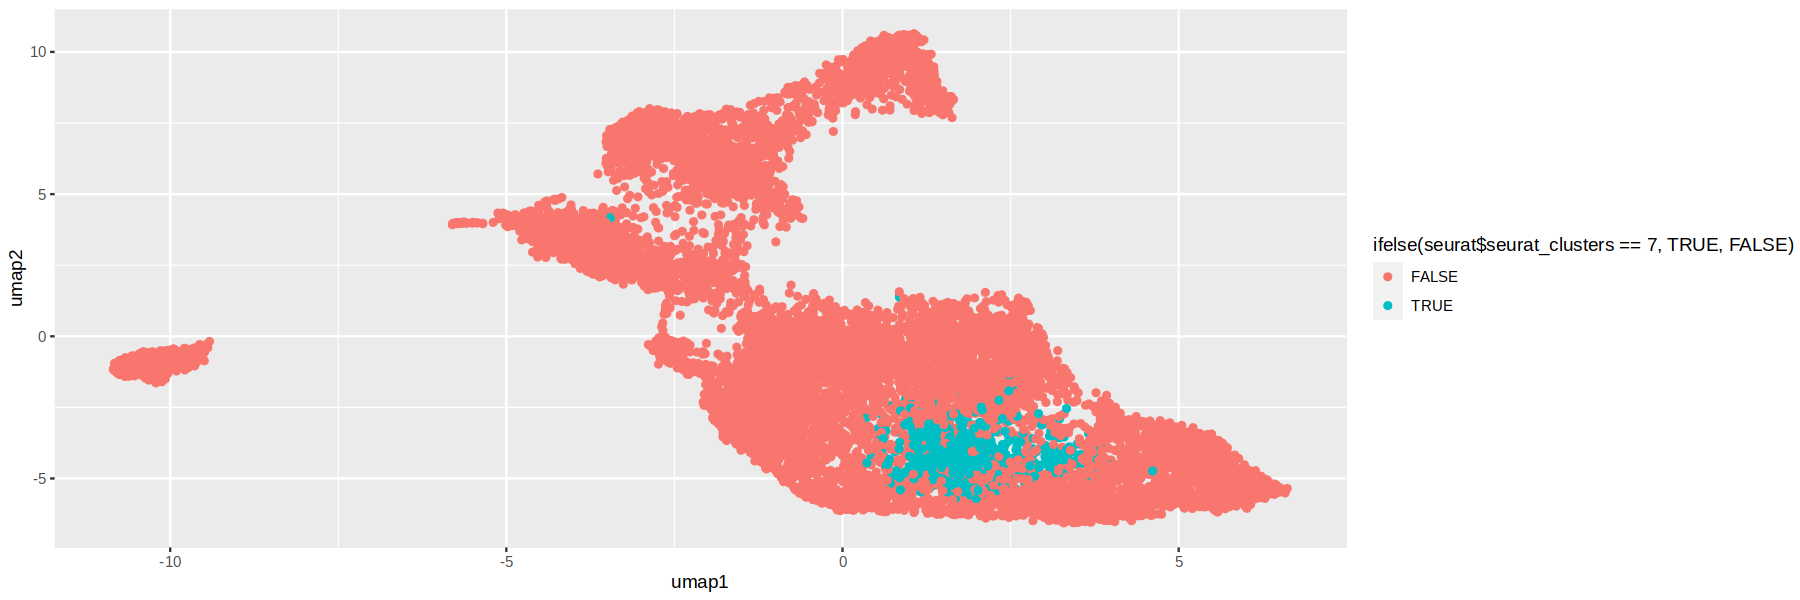

In [24]:
options(repr.plot.width = 15, repr.plot.height = 5)

ggplot(d45_umap, aes(umap1, umap2, color = ifelse(seurat$seurat_clusters == 7, TRUE, FALSE))) + geom_point() 

In [25]:
cluster2celltype

0                      1                      2 
"Pre-somitic mesoderm" "Pre-somitic mesoderm"             "Ectoderm" 
                     3                      4                      5 
"Pre-somitic mesoderm"          "Notochord 1"               "DE/Gut" 
                     6                      7                      8 
         "Notochord 2"    "Paraxial mesoderm"    "Paraxial mesoderm" 
                     9                     10                     11 
   "Paraxial mesoderm"           "Mesenchyme"           "Mesenchyme" 
                    12                     13 
     "Pluripotent/PGC"          "Low quality"

In [26]:
d45_meta = as.data.table(seurat@meta.data, keep.rownames = T) %>%
    setnames('rn', 'cell') %>%
    .[, celltype_manual := cluster2celltype[match(seurat_clusters, names(cluster2celltype))]]

In [27]:
unique(d45_meta$celltype_manual)

[1] "Ectoderm"             "Pre-somitic mesoderm" "Paraxial mesoderm"   
[4] "Pluripotent/PGC"      "Mesenchyme"           "Low quality"         
[7] "Notochord 1"          "DE/Gut"               "Notochord 2"

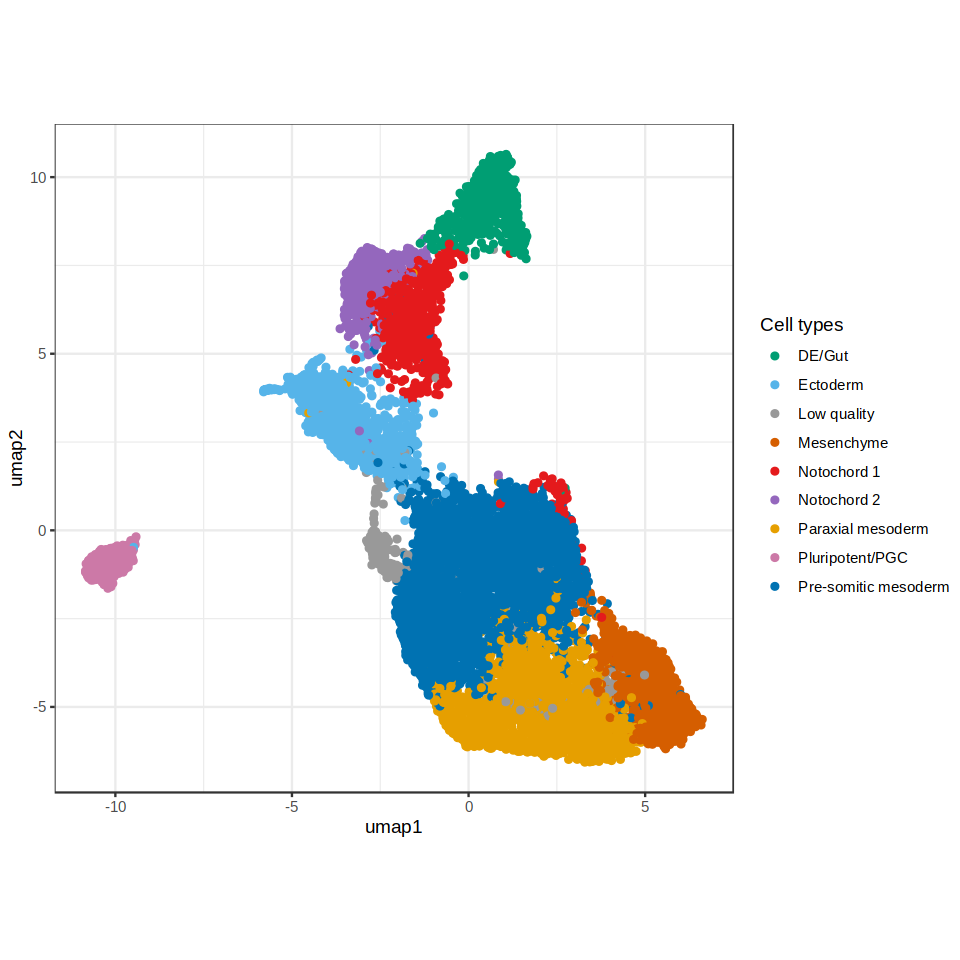

In [28]:
cell_colors <- c(
  'Ectoderm'  = "#56B4E9",
  "Paraxial mesoderm" = "#E69F00",
  "Mesenchyme"        = "#D55E00",
  "Pre-somitic mesoderm"     = "#0072B2",
  "Pluripotent/PGC"   = "#CC79A7",
  "Low quality"       = "#999999",
  "Notochord 1"          = "#E41A1C",
  "DE/Gut"            = "#009E73",
  "Notochord 2"         = "#9467BD"
)

options(repr.plot.width = 8, repr.plot.height = 8)
ggplot(d45_umap, aes(umap1, umap2, color = d45_meta$celltype_manual)) + 
    geom_point() +
    coord_fixed() + 
    scale_color_manual(values = cell_colors, name = 'Cell types') + 
    theme_bw()

In [29]:
args$outdir

[1] "/rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/results/manuscript/day_45_v2/"

In [30]:
fwrite(d45_meta, file.path(args$outdir, 'd45_celltypes.txt.gz'))
fwrite(d45_umap, file.path(args$outdir, 'd45_umap.txt.gz'))


In [31]:
meta = fread(file.path(args$outdir, 'd45_celltypes.txt.gz'))
umap = fread(file.path(args$outdir, 'd45_umap.txt.gz'))

In [32]:
meta = merge(meta, umap, by = 'cell') %>%
    .[,genotype := gsub('_KO', ' KD', genotype)]

In [33]:
p1 = ggplot(meta, aes(umap1, umap2, color = celltype_manual)) + 
    ggrastr::rasterize(geom_point(size = -0.2), dpi = 600) + 
    guides(color = guide_legend(override.aes = list(size = 2.5))) + # Set legend dot size 
    scale_color_manual(values = cell_colors, name = 'Cell types') + 
    theme_void() + 
    theme(legend.key.size = unit(1.2, "mm"))

p2 = ggplot(copy(meta)[genotype == 'WT'], aes(umap1, umap2, color = celltype_manual)) + 
    ggrastr::rasterize(geom_point(data = meta[genotype == 'Eomes KD'], color = 'grey90', size = -0.2), dpi = 600) + 
    ggrastr::rasterize(geom_point(size = -0.2), dpi = 600) + 
    scale_color_manual(values = cell_colors, name = 'Cell types') + 
    ggtitle('WT') + 
    guides(color = guide_legend(override.aes = list(size = 2.5))) + # Set legend dot size 
    theme_void()  + theme(legend.position = 'none',
                         plot.title = element_text(hjust = 0.5)
                          )

p3 = ggplot(copy(meta)[genotype == 'Eomes KD'], aes(umap1, umap2, color = celltype_manual)) + 
    ggrastr::rasterize(geom_point(data = meta[genotype == 'WT'], color = 'grey90', size = -0.2), dpi = 600) + 
    ggrastr::rasterize(geom_point(size = -0.2), dpi = 600) + 
    scale_color_manual(values = cell_colors, name = 'Cell types') + 
    ggtitle('EOMES-KD') + 
    guides(color = guide_legend(override.aes = list(size = 2.5))) + # Set legend dot size 
    theme_void() + theme(legend.position = 'none',
                         plot.title = element_text(hjust = 0.5)
                        )

meta_props = meta %>% copy() %>%
    .[, tot := .N, by = 'genotype'] %>%
    .[, prop := .N/tot, by = c('celltype_manual', 'genotype')] %>%
    unique(by = c('celltype_manual', 'genotype')) %>%
    .[, genotype := factor(genotype, levels = c('WT', 'Eomes KD'))]

p4 = ggplot(meta_props, aes(celltype_manual, prop * 100, fill = genotype)) +
    geom_bar(position = 'dodge', stat = 'identity') + 
    scale_fill_manual(values = c('Eomes KD' = 'red', 'WT' = 'black')) +
    scale_y_continuous(expand = c(0,0,0.05,0)) + 
    scale_x_discrete(limits = c(        
                                "DE/Gut",
                                "Notochord 1",
                                "Notochord 2",
                                "Paraxial mesoderm",
                                "Mesenchyme",
                                "Pre-somitic mesoderm",
                                'Ectoderm',
                                "Pluripotent/PGC"
                                )) + 
    ylab('% of genotype') + 
    theme_bw() + 
    theme(axis.text = element_text(color = 'black'),
          axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5),
          axis.title.x = element_blank())

                      
# p4

Warning message:
“Removed 2 rows containing missing values (`geom_bar()`).”


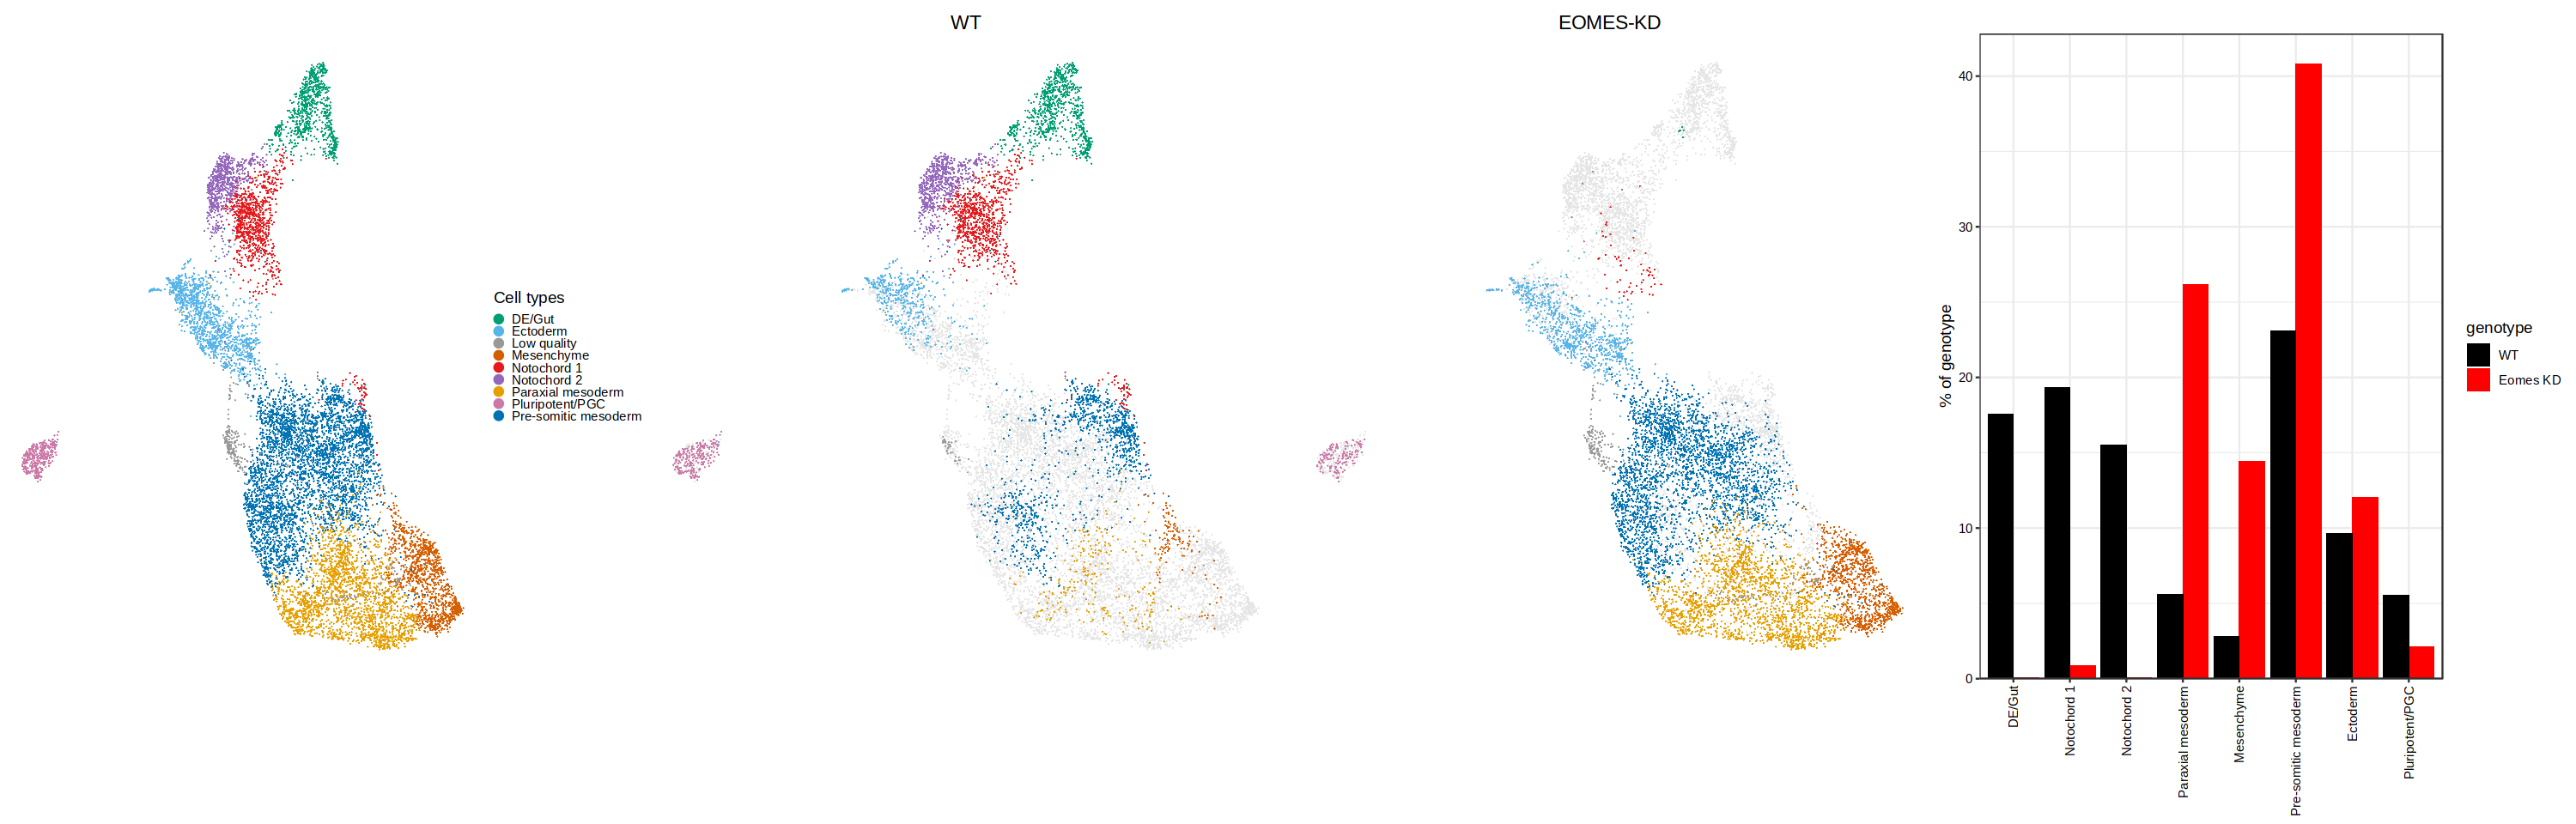

In [34]:
options(repr.plot.width = 25)
ggarrange(p1, p2, p3, p4, ncol = 4, align = 'h')


In [35]:
ggsave(file.path(args$outdir, 'UMAPs_proportions.pdf'), 
       plot = ggarrange(cowplot::ggdraw(get_legend(p1)), p2, p3, p4, ncol = 4, widths = c(0.4, 0.8, 0.8, 1)),
       width = 250, 
       height = 60, 
       units = "mm")

Warning message:
“Removed 2 rows containing missing values (`geom_bar()`).”


In [36]:
head(markers)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
Fat3,0.000000e+00,0.7754217,0.979,0.677,0.000000e+00,0,Fat3
Kcnh5,1.049829e-259,0.8067864,0.521,0.151,3.389372e-255,0,Kcnh5
Pdzrn3,3.299257e-221,0.4792680,0.994,0.827,1.065165e-216,0,Pdzrn3
Maml3,5.075298e-208,0.3369510,0.994,0.932,1.638560e-203,0,Maml3
Gpc6,1.469646e-203,0.3057723,1.000,0.951,4.744752e-199,0,Gpc6
Limch1,3.214781e-201,0.6431225,0.898,0.581,1.037892e-196,0,Limch1


In [37]:
seurat@meta.data = meta %>% as.data.frame() %>% tibble::column_to_rownames('cell') %>% as.data.frame()

In [38]:
Idents(seurat) = seurat@meta.data$celltype_manual

Calculating cluster Ectoderm

Calculating cluster Pre-somitic mesoderm

Calculating cluster Paraxial mesoderm

Calculating cluster Pluripotent/PGC

Calculating cluster Mesenchyme

Calculating cluster Low quality

Calculating cluster Notochord 1

Calculating cluster DE/Gut

Calculating cluster Notochord 2



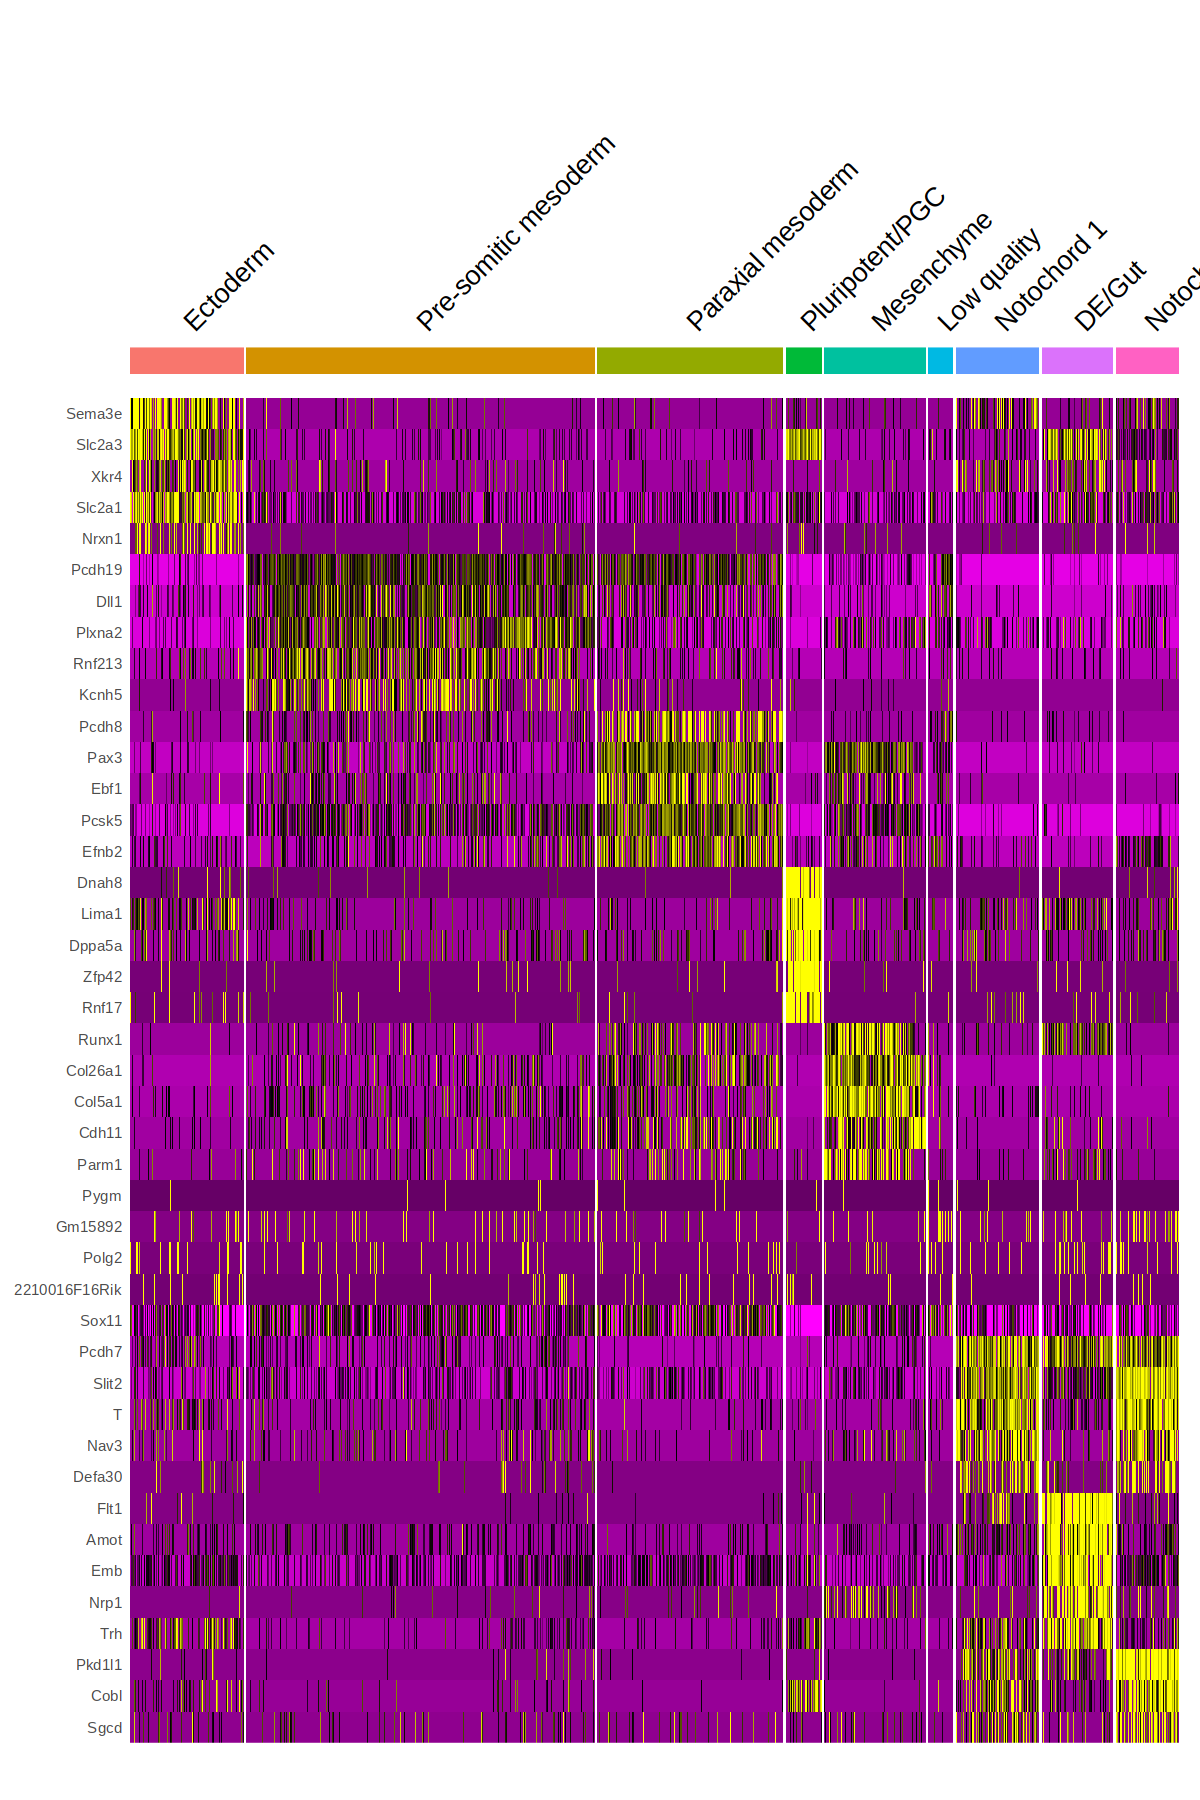

In [39]:
# find markers for every cluster compared to all remaining cells, report only the positive
# ones
markers <- FindAllMarkers(seurat, only.pos = TRUE)
markers %>%
    group_by(cluster) %>%
    # dplyr::filter(avg_log2FC > 1) %>%
    slice_head(n = 5) %>%
    ungroup() -> top

options(repr.plot.width = 10, repr.plot.height = 15)
DoHeatmap(seurat, features = top$gene) + NoLegend()

In [40]:
lapply(unique(Idents(seurat)), function(i){
  sprintf('%s: %s', i, paste(as.data.table(markers)[cluster == i, ]$gene %>% head(15), collapse = ', '))
})

[[1]]
[1] "Ectoderm: Sema3e, Slc2a3, Xkr4, Slc2a1, Nrxn1, Frem2, Bst2, Fgfbp3, Wnt8a, Pla2g7, F2rl1, Lrp2, Dgkb, Pcdh1, Cdh1"

[[2]]
[1] "Pre-somitic mesoderm: Pcdh19, Dll1, Plxna2, Rnf213, Kcnh5, Dach1, Smoc1, Arhgap24, Aldh1a2, Rspo3, Robo2, Lef1, Meis2, Kcnh7, Pdzrn3"

[[3]]
[1] "Paraxial mesoderm: Pcdh8, Pax3, Ebf1, Pcsk5, Efnb2, Fbn2, Zfp536, Myocd, Kcnc2, Sim1, Snap91, Maml2, Nrp2, Ltbp1, Ptn"

[[4]]
[1] "Pluripotent/PGC: Dnah8, Lima1, Dppa5a, Zfp42, Rnf17, 9330185C12Rik, Pdzrn4, Sox2, Spp1, Tfcp2l1, Abcc4, Zfp980, Zfp981, Jade1, Nr5a2"

[[5]]
[1] "Mesenchyme: Runx1, Col26a1, Col5a1, Cdh11, Parm1, Acss1, Nav1, Itga9, Creb5, Mir100hg, Hs3st3a1, Col1a1, Loxl2, Morrbid, Loxl1"

[[6]]
[1] "Low quality: Pygm, Gm15892, Polg2, 2210016F16Rik, Sox11, Rbbp6, Usp3, G630016G05Rik, Cep76, Mapk8, Peli1, Gm49692, Ube2q2, Ninl, Mcmbp"

[[7]]
[1] "Notochord 1: Pcdh7, Slit2, T, Nav3, Defa30, Trim67, Pde4d, Shh, Lefty1, Pkd1l1, Fgf8, Klhl32, Cthrc1, Cobl, Lypd6b"

[[8]]
[1] "DE/Gut: Flt1, Amot, Emb, Nrp1, Trh, 9030622O22Rik, Fgf5, Dkk1, Otx2, Igfbp2, Cacna2d3, Car4, Fzd5, Kit, Cfap299"

[[9]]
[1] "Notochord 2: Pkd1l1, Cobl, Slit2, T, Sgcd, Bicc1, 9030622O22Rik, Gpc5, Cthrc1, Frem2, Cldn6, Defa30, Cfc1, Lypd6b, Chrd"

In [41]:
seurat$celltype_genotype = paste0(seurat$celltype_manual, ' (', gsub('Eomes ', '', seurat$genotype), ')')
seurat$celltype_genotype = factor(seurat$celltype_genotype, 
                                  levels = c(
                                      'DE/Gut (WT)', 
                                      'DE/Gut (KD)', 
                                      'Notochord 1 (WT)',
                                      'Notochord 1 (KD)',
                                      'Notochord 2 (WT)', 
                                      'Notochord 2 (KD)',                                       
                                      'Mesenchyme (WT)',
                                      'Mesenchyme (KD)',
                                      'Paraxial mesoderm (WT)',
                                      'Paraxial mesoderm (KD)',
                                      'Pre-somitic mesoderm (WT)',
                                      'Pre-somitic mesoderm (KD)',
                                      'Ectoderm (WT)',
                                      'Ectoderm (KD)',
                                      'Pluripotent/PGC (WT)',
                                      'Pluripotent/PGC (KD)',
                                      'Low quality (WT)',
                                      'Low quality (KD)'
                                    )
                                  )

In [42]:
unique(paste0(seurat$celltype_manual, ' (', gsub('Eomes ', '', seurat$genotype), ')'))

[1] "Ectoderm (KD)"             "Pre-somitic mesoderm (KD)"
 [3] "Paraxial mesoderm (KD)"    "Pluripotent/PGC (KD)"     
 [5] "Mesenchyme (KD)"           "Low quality (KD)"         
 [7] "Notochord 1 (KD)"          "DE/Gut (KD)"              
 [9] "Notochord 2 (KD)"          "Notochord 1 (WT)"         
[11] "Notochord 2 (WT)"          "DE/Gut (WT)"              
[13] "Ectoderm (WT)"             "Pre-somitic mesoderm (WT)"
[15] "Pluripotent/PGC (WT)"      "Mesenchyme (WT)"          
[17] "Paraxial mesoderm (WT)"    "Low quality (WT)"

In [43]:
seurat_filt = seurat[, ! seurat@meta.data$celltype_genotype %in% 
                     c(
                      'DE/Gut (KD)', 
                      'Notochord 1 (KD)',
                       'Notochord 2 (KD)',
                    'Low quality (WT)',
                    'Low quality (KD)'
                     )
                    ]

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


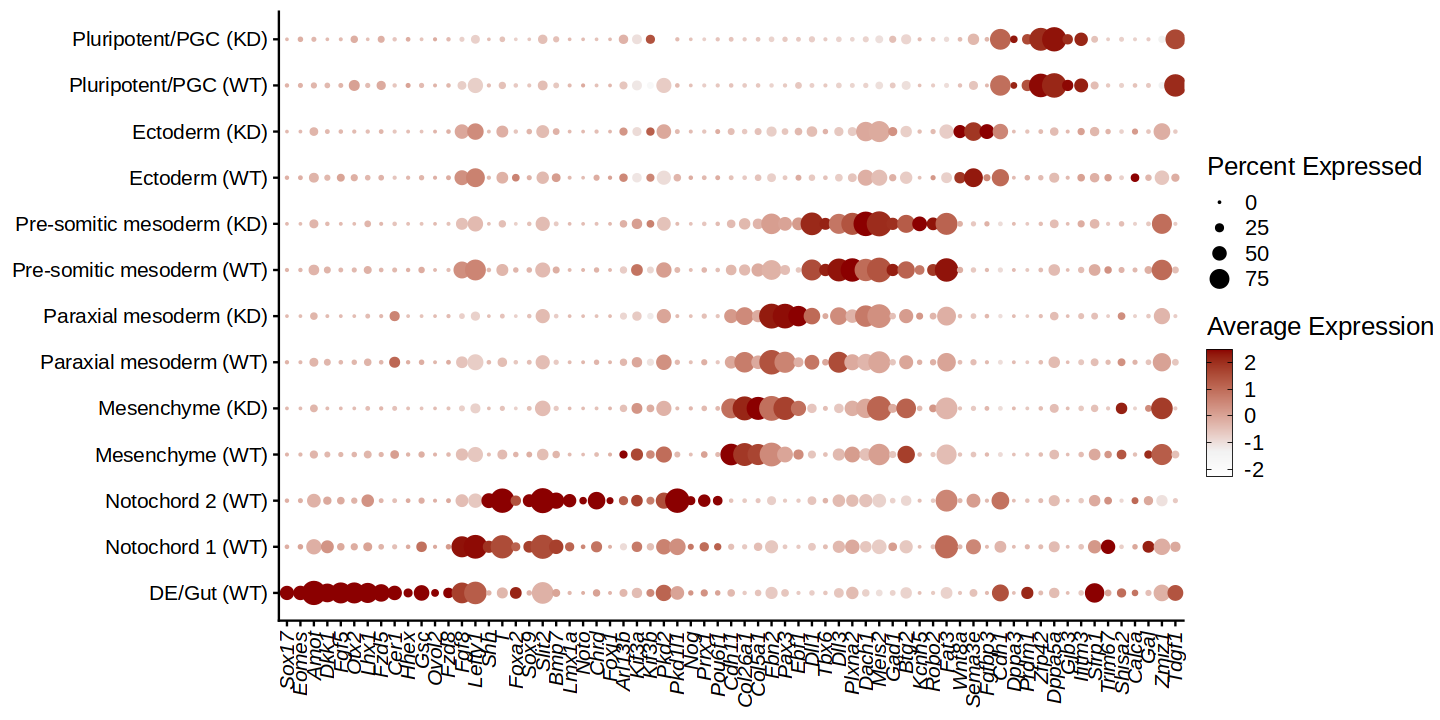

In [44]:
features = c(
    'Sox17', 'Eomes', 'Amot', 'Dkk1', 'Fgf5', 'Otx2', 'Lhx1', 'Fzd5', 'Cer1', 'Hhex','Gsc', 'Ovol2', 'Fzd8',   # 'Emb', 'Trh', 'Nrp1', 
    'Fgf8', 'Lefty1', 'Shh', 'T',  # APS
    'Foxa2', 'Sox9', 'Slit2', 'Bmp7', 'Lmx1a', 'Noto','Chrd', 'Foxj1', 'Arl13b', 'Kif3a', 'Kif3b', 'Pkd2', 'Pkd1l1',    # Notochord
    'Nog', 'Prrx1', 'Pou6f1', 
    # 'Foxa2', 'Slit2', 'Bmp7', 'Lmx1a', 'Noto','Chrd', 'Arl13b', 'Kif3a', 'Pkd1l1',  # Notochord
    'Cdh11', 'Col26a1', 'Col5a1','Fbn2','Pax3', 'Ebf1',   # Parax. Mes.
    'Dll1', 'Tbx6', 'Dll3', 'Plxna2', 'Dach1', 'Meis2', # Som. Mes.
    'Gad1', 'Btg2', 'Kcnh5', 'Robo2', 'Fat3',
    'Wnt8a', 'Sema3e', 'Fgfbp3', 'Cdh1', # Ectoderm-like
    'Dppa3', 'Prdm1', 'Zfp42', 'Dppa5a','Gjb3', 'Ifitm3', # PGC
    'Sfrp1', 'Trim67', 'Shisa2', 'Calca', 'Gal', 'Zmiz1','Tdgf1'
    
)

options(repr.plot.width=12, repr.plot.height=6)
p = DotPlot(seurat_filt, features = features, group.by = 'celltype_genotype') + 
    # scale_color_gradient(low='white', high='darkred', name='Average Expression') + 
    scale_color_gradientn(colours = c('white', 'grey95','darkred'), values = c(0, 0.2,1), name='Average Expression') + 
    guides(color = guide_colourbar(
         # barwidth = 0.5, barheight = 2.5,
        frame.colour = "black", 
        ticks.colour = "black"
    )) + 
    RotatedAxis() +
    ylab('celltype genotype') + xlab('') +
    theme(text=element_text(size=15), 
                         axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5, face = 'italic'),
                         axis.text.y=element_text(hjust=1),
         axis.title = element_blank())

p

In [45]:
ggsave(file.path(args$outdir, 'd45_expression.pdf'), 
       plot = p,
       width = 380, 
       height = 95, 
       units = "mm")

In [46]:
markers %>%
    group_by(cluster) %>%
    # dplyr::filter(avg_log2FC > 1) %>%
    slice_head(n = 15) %>%
    ungroup() -> top30

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


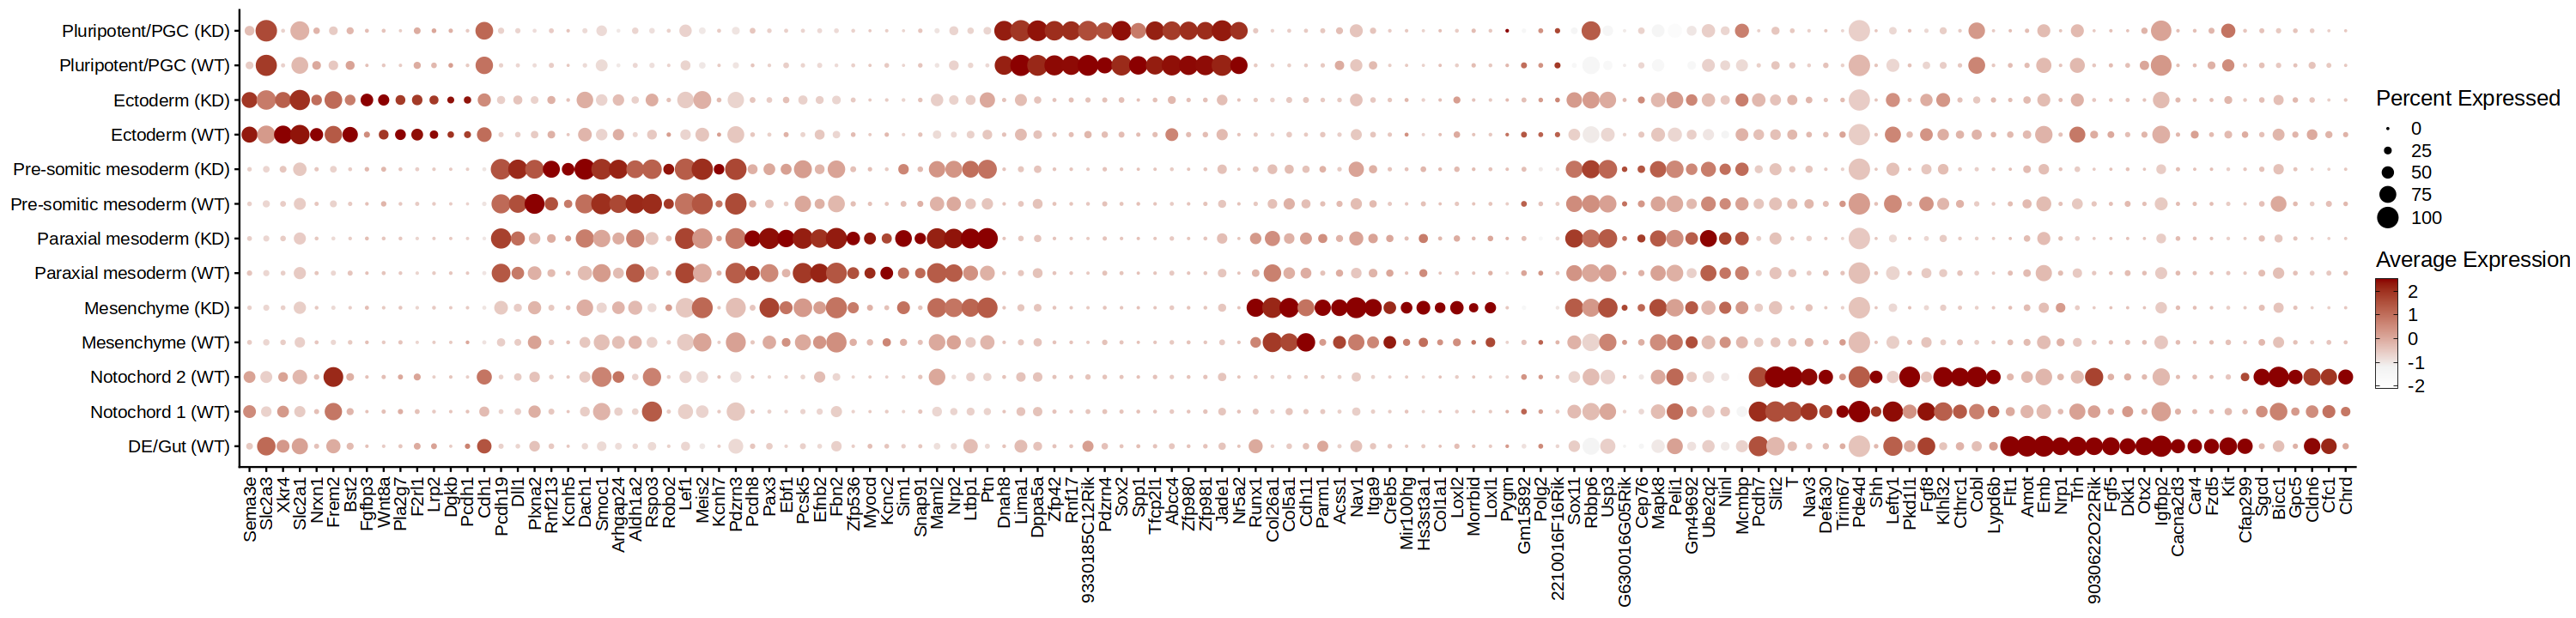

In [47]:
options(repr.plot.width=25, repr.plot.height=6)
p = DotPlot(seurat_filt, features = unique(top30$gene), group.by = 'celltype_genotype') + 
    # scale_color_gradient(low='white', high='darkred', name='Average Expression') + 
    scale_color_gradientn(colours = c('white', 'grey95','darkred'), values = c(0, 0.2,1), name='Average Expression') + 
    guides(color = guide_colourbar(
         # barwidth = 0.5, barheight = 2.5,
        frame.colour = "black", 
        ticks.colour = "black"
    )) + 
    RotatedAxis() +
    ylab('celltype genotype') + xlab('') +
    theme(text=element_text(size=15), 
                         axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5),
                         axis.text.y=element_text(hjust=1),
         axis.title = element_blank())

p

In [48]:
colnames(seurat@meta.data)

[1] "orig.ident"                "nCount_RNA"               
 [3] "nFeature_RNA"              "barcode"                  
 [5] "sample"                    "mitochondrial_percent_RNA"
 [7] "ribosomal_percent_RNA"     "alias"                    
 [9] "day"                       "genotype"                 
[11] "pass_rnaQC"                "doublet_score"            
[13] "doublet_call"              "celltype"                 
[15] "celltype.score"            "closest.cell"             
[17] "day_celltype"              "celltype_genotype"        
[19] "TSSEnrichment_atac"        "ReadsInTSS_atac"          
[21] "PromoterRatio_atac"        "NucleosomeRatio_atac"     
[23] "nFrags_atac"               "BlacklistRatio_atac"      
[25] "pass_atacQC"               "RNA_snn_res.0.9"          
[27] "seurat_clusters"           "celltype_manual"          
[29] "umap1"                     "umap2"

In [49]:
Idents(seurat) = seurat@meta.data$celltype_genotype

In [50]:
markers = FindMarkers(seurat,   ident.1 = 'Notochord 1 (WT)',
  ident.2 = 'Notochord 2 (WT)')
markers$gene = rownames(markers)

In [51]:
getwd()

[1] "/rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/code/Manuscript"

In [52]:
fwrite(markers, '/rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/results/manuscript/day_45_v2/notochord_markers.csv')

In [53]:
atlas = fread(io$rna.atlas.metadata)

In [54]:
head(atlas)

cell,barcode,sample,stage,sequencing.batch,doublet,stripped,celltype,umapX,umapY,nFeature_RNA,nCount_RNA
<chr>,<chr>,<int>,<chr>,<int>,<lgl>,<lgl>,<chr>,<dbl>,<dbl>,<int>,<int>
cell_1,AAAGGCCTCCACAA,1,E6.5,1,FALSE,FALSE,Epiblast,-10.2275459,-2.8816875,2547,8963
cell_10,AACTGTCTTCGCAA,1,E6.5,1,FALSE,FALSE,Epiblast,-11.2435319,-0.8761099,1933,5643
cell_100,CACAGATGGGGACA,1,E6.5,1,FALSE,FALSE,Epiblast,-10.9044295,-0.9639773,4278,24947
cell_1000,GCCACTACCCGCTT,3,E7.5,1,FALSE,FALSE,Caudal_epiblast,-2.9437001,-0.7820226,2829,9294
cell_10000,GTAGGTACGTGTTG,8,E7.75,1,FALSE,FALSE,Rostral_neurectoderm,-7.3668170,-2.2819553,4492,24351
cell_100000,GACTGATGACACAC,29,E8.5,3,FALSE,FALSE,Forebrain_Midbrain_Hindbrain,-0.9185215,-5.5175930,3217,14074


In [55]:
meta2 = cbind(meta, atlas[match(meta$closest.cell, cell), .(umapX, umapY)])

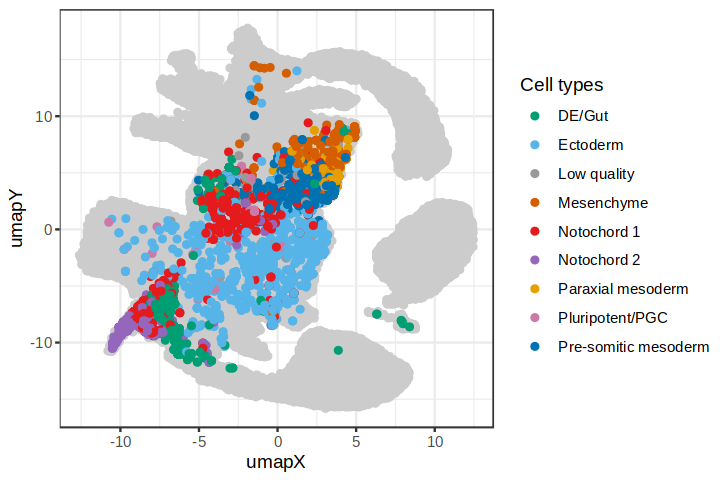

In [56]:
options(repr.plot.width = 6, repr.plot.height = 4)
ggplot(meta2, aes(umapX, umapY, color = celltype_manual)) + 
    geom_point(data = atlas, color = 'grey80') +
    geom_point() +
    scale_color_manual(values = cell_colors, name = 'Cell types') + 
    theme_bw()

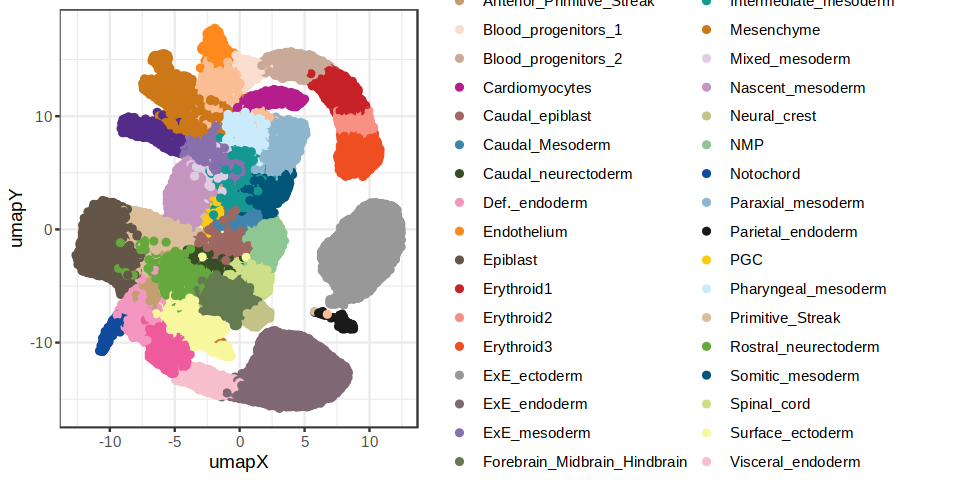

In [57]:
options(repr.plot.width = 8, repr.plot.height = 4)

ggplot(atlas, aes(umapX, umapY, color = celltype)) + 
    geom_point() +
    scale_color_manual(values = opts$celltype.colors, name = 'Cell types') + 
    theme_bw()

In [58]:
umap_gene = function(gene){
    message(gene)
    tmp = meta %>% copy() %>%
        .[, expression := as.vector(seurat@assays$RNA@data[gene,meta$cell])] %>%
        .[order(expression)] %>%
        .[celltype_manual %in% c('Notochord 1', 'Notochord 2', 'DE/Gut') & genotype == 'WT'] 
    
    p = ggplot(tmp, aes(umap1, umap2, color = expression)) + 
        geom_point(size = 0.2) + 
        # facet_wrap(~genotype) +
        scale_color_gradientn(colors = c('blue', 'yellow', 'red'), name = 'Expression', breaks = c(0, max(tmp$expression)), labels = c('min', 'max')) +
        ggtitle(gene) + 
        coord_fixed() + 
        theme_void() + 
        theme(strip.text = element_text(size = 5),
              plot.title = element_text(size = 7, face = 'bold', hjust = 0.5)
              )
    
    return(p)
}

Noto

Chrd

Shh

T

Fgf8

Cer1

Dkk1

Lefty1

Sfrp1

Sfrp2

Adamts9

Gsc

Eomes

Foxa2

Isl1

Epb41l5



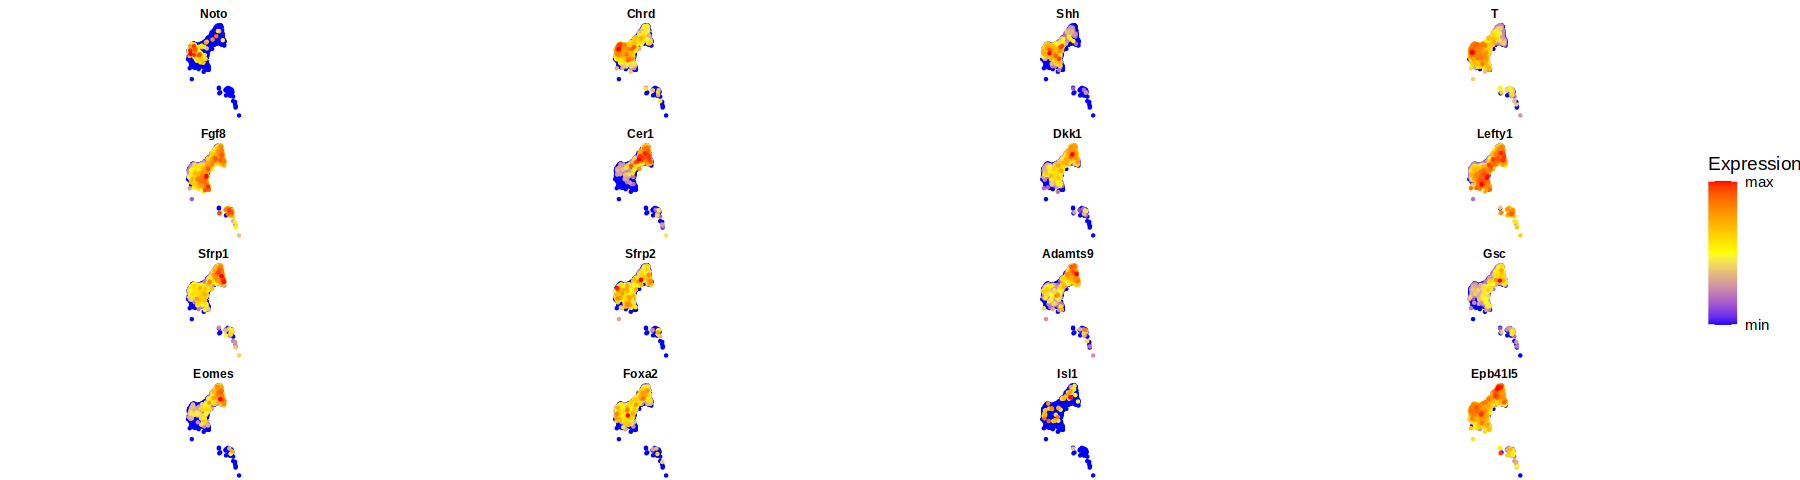

In [59]:
options(repr.plot.width = 15)
genes = c('Noto', 'Chrd','Shh', 'T', 'Fgf8',
    'Cer1', 'Dkk1', 'Lefty1', 'Sfrp1', 'Sfrp2', 'Adamts9', 'Gsc', 'Eomes', 'Foxa2', 'Isl1',  'Epb41l5')
# genes = c('Noto', 'Chrd','Shh')
  
plots = mclapply(genes, umap_gene, mc.cores = 1)
ggpubr::ggarrange(plotlist = plots,
  common.legend = TRUE,
  legend = "right")

In [60]:
ggsave(file.path(args$outdir, 'umap_expression.pdf'), 
       plot = ggpubr::ggarrange(plotlist = plots,
              common.legend = TRUE,
              legend = "right"),
       width = 300, 
       height = 400, 
       units = "mm")

Sox17

Pkd1l1

Gal

Tdgf1



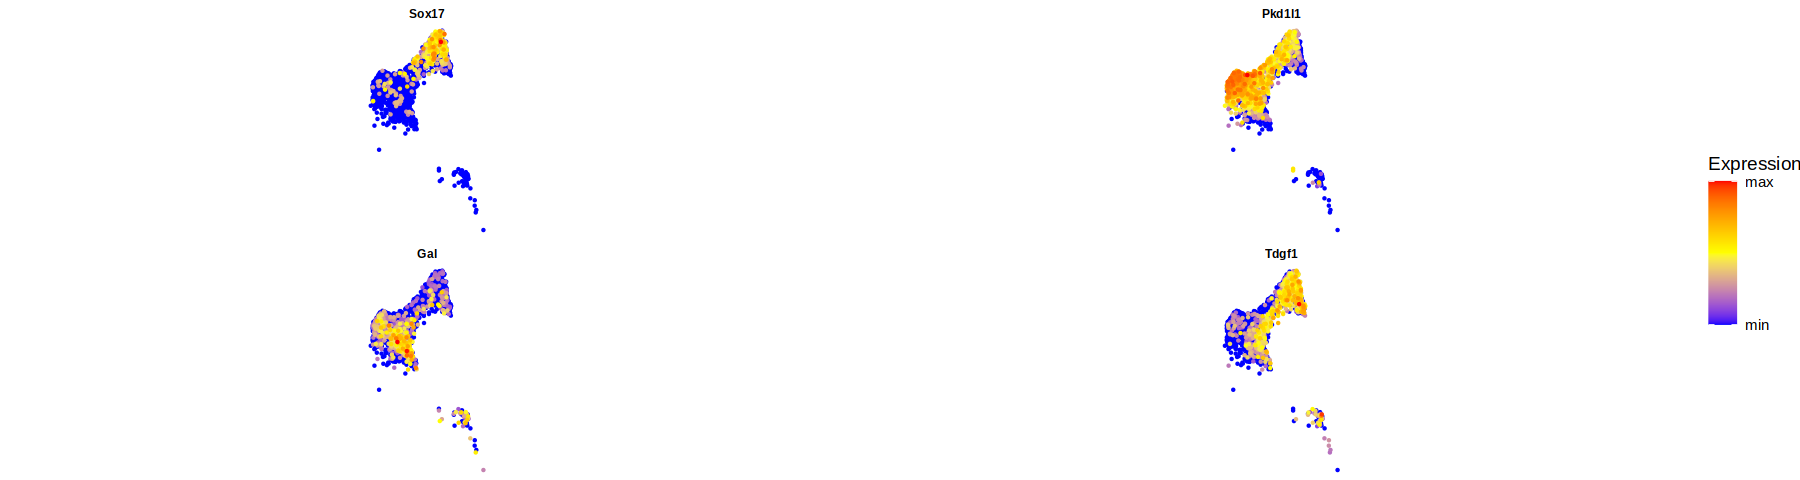

In [68]:
options(repr.plot.width = 15)
genes = c('Sox17', 'Pkd1l1', 'Gal', 'Tdgf1')
# genes = c('Noto', 'Chrd','Shh')
  
plots = mclapply(genes, umap_gene, mc.cores = 1)
ggpubr::ggarrange(plotlist = plots,
  common.legend = TRUE,
  legend = "right")

In [69]:
ggsave(file.path(args$outdir, 'umap_expression2.pdf'), 
       plot = ggpubr::ggarrange(plotlist = plots,
              common.legend = TRUE,
              legend = "right", nrow = 1),
       width = 300, 
       height = 400, 
       units = "mm")

# Spatial mapping

In [61]:
getwd()

[1] "/rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/code/Manuscript"

In [62]:
background = as.data.table(readRDS('/rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/results/manuscript/spatial_mapping/seqFISH_subset4_7_2024_for_Bart_spatial_mapping.rds'), keep.rownames = 'cell')

In [63]:
mapped = readRDS('/rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/results/manuscript/spatial_mapping/seurat_object.rds')

In [64]:
mapping = as.data.table(readRDS('/rds/project/rds-SDzz0CATGms/users/bt392/10_Eomes_invitro_gut/results/manuscript/spatial_mapping/merged_query_meta.Rds'))

In [65]:
seurat$dim1 = mapping[match(colnames(seurat),cell_ID)]$dim1
seurat$dim2 = mapping[match(colnames(seurat),cell_ID)]$dim2
seurat$embryo = mapping[match(colnames(seurat),cell_ID)]$embryo
seurat$joint_clusters_pass_QC = mapping[match(colnames(seurat),cell_ID)]$joint_clusters_pass_QC
seurat$joint_clusters_pass_QC = mapping[match(colnames(seurat),cell_ID)]$joint_clusters_pass_QC

In [85]:
meta = as.data.table(seurat@meta.data, keep.rownames = 'cell')
meta$genotype = factor(meta$genotype, levels = c('WT', 'Eomes KD'))

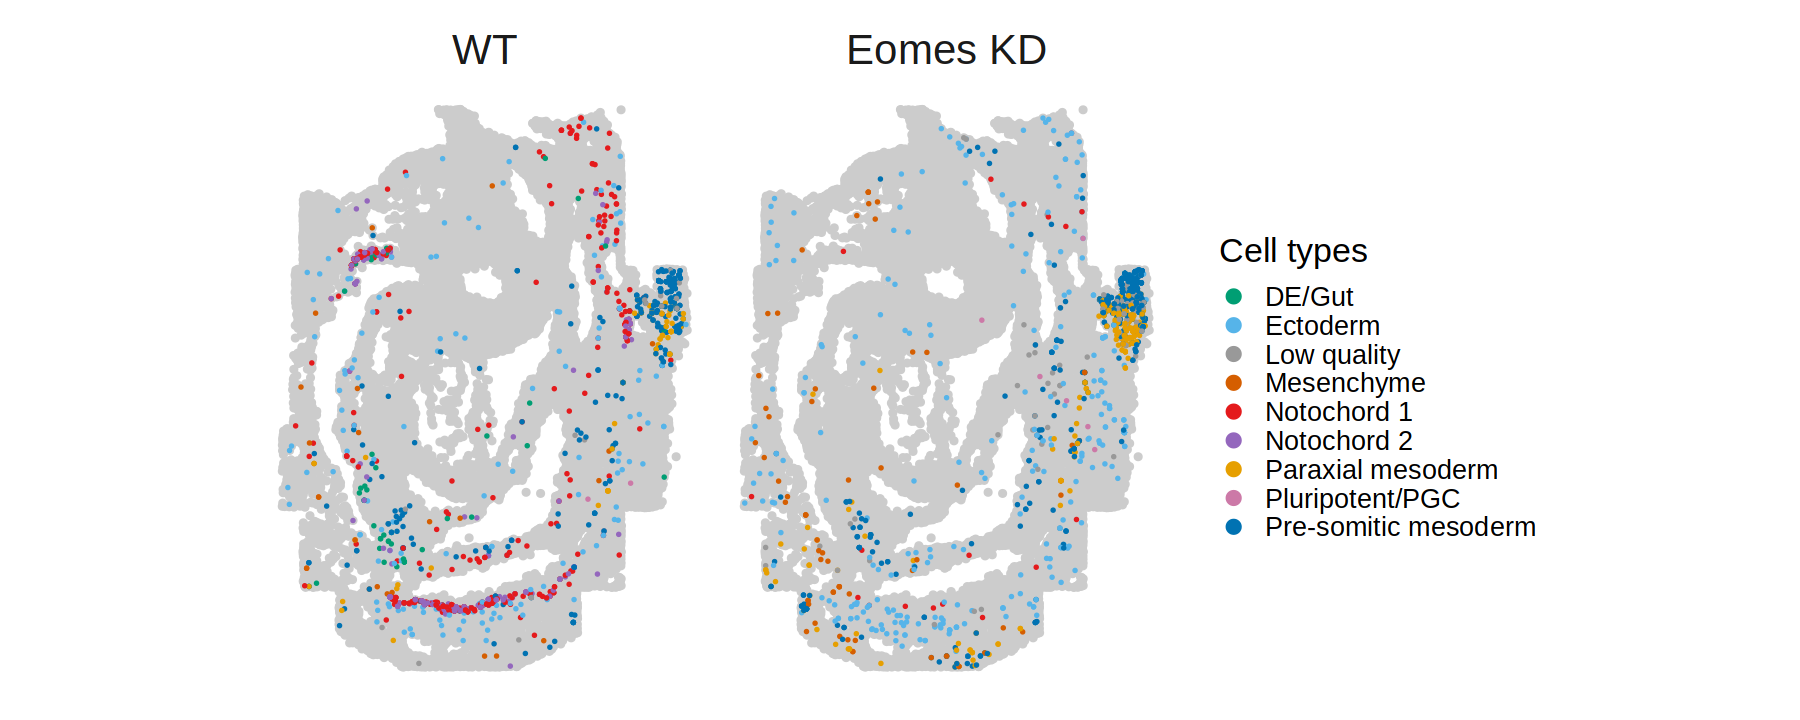

In [86]:
options(repr.plot.width=15, repr.plot.height=6)
ggplot(, aes(dim1, dim2)) + 
  geom_point(data = background[embryo == 'embryo1'], color = 'grey80') + 
  geom_point(data = meta[embryo == 'embryo1'], aes(color = celltype_manual), size = 0.5) +
  scale_color_manual(values = cell_colors, name = 'Cell types') + 
  coord_fixed() + 
  facet_wrap(~genotype) + 
guides(color = guide_legend(override.aes = list(size = 3.5))) + # Set legend dot size 
  theme_bw(base_size = 20) +
  theme(
    axis.text = element_blank(),
    axis.ticks = element_blank(),
    axis.title = element_blank(),
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank(),
    strip.background = element_blank(),
    strip.text = element_text(size = 25),
    panel.border = element_blank()
  )

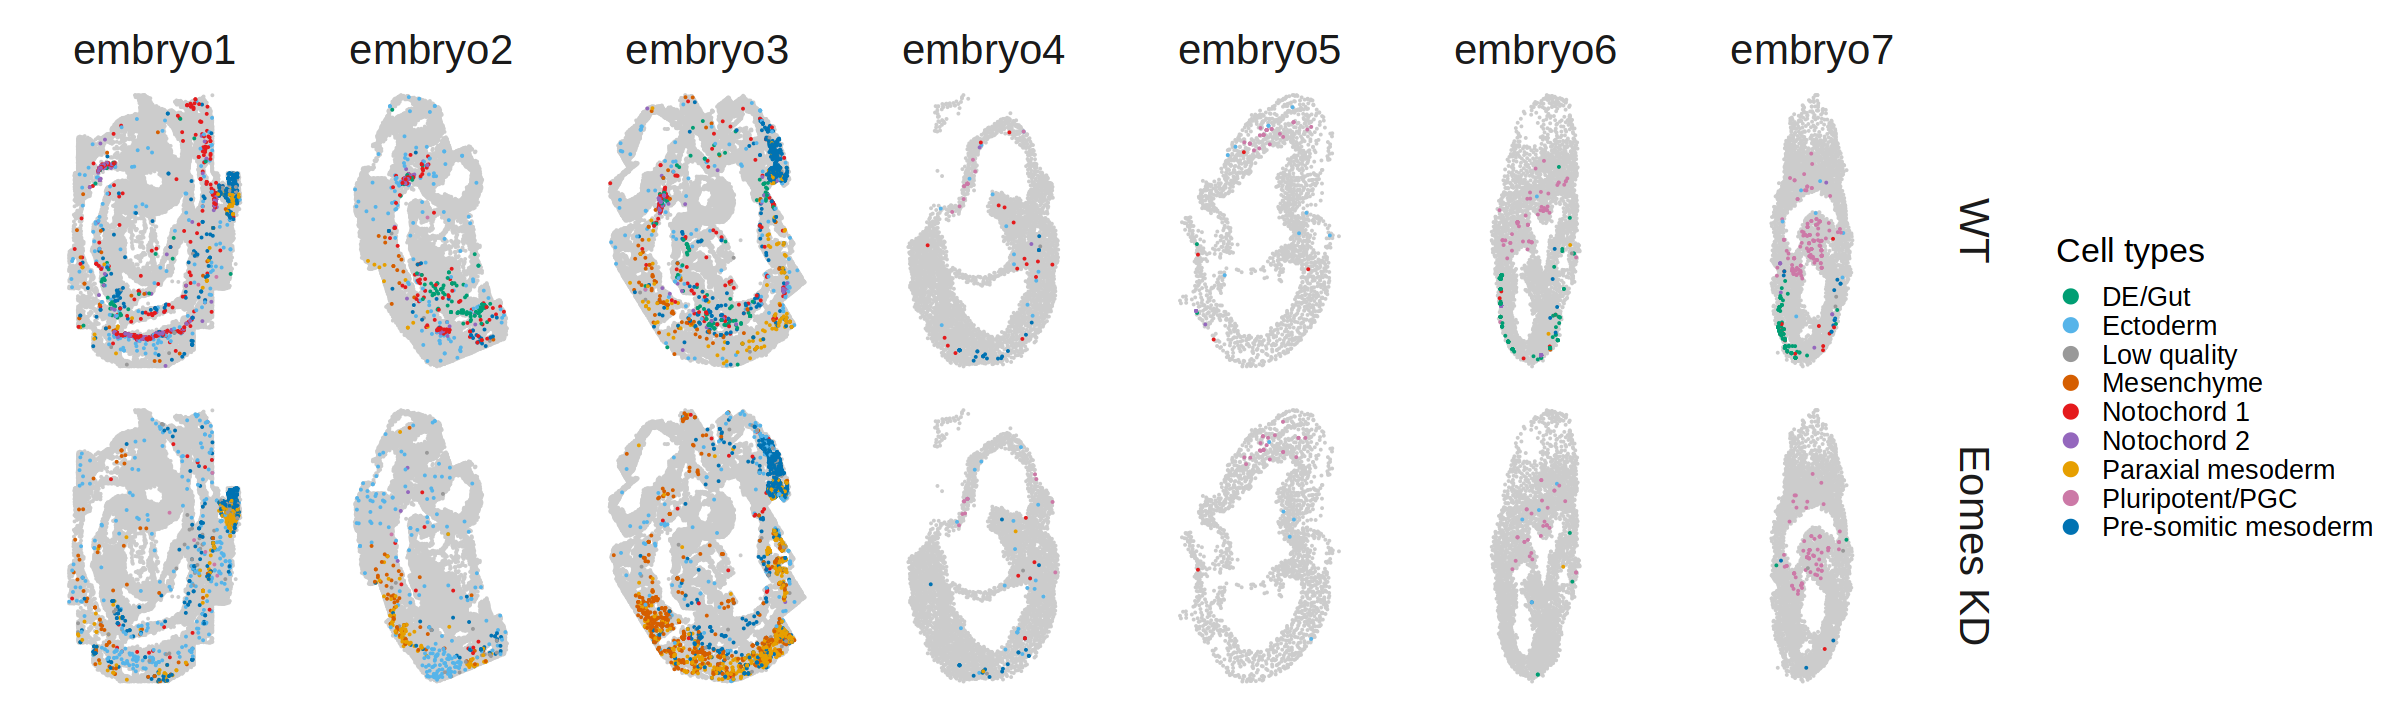

In [87]:
options(repr.plot.width = 20, repr.plot.height = 6)

# 1. Combine meta and background into the unified plotting table first
plot <- rbind(
  meta[, s := 'data'], 
  background[, s := 'background'] %>% copy() %>% .[, genotype := 'Eomes KD'], 
  background[, s := 'background'] %>% copy() %>% .[, genotype := 'WT'], 
  fill = TRUE
)

# 2. Joint, centered 1:1 aspect ratio normalization function per embryo
rs_joint_centered <- function(x, y) {
  rx <- range(x, na.rm = TRUE)
  ry <- range(y, na.rm = TRUE)
  
  dx <- diff(rx)
  dy <- diff(ry)
  max_diff <- max(dx, dy)
  
  # Scale by max_diff to preserve physical aspect ratio
  x_scaled <- (x - rx[1]) / max_diff
  y_scaled <- (y - ry[1]) / max_diff
  
  # Center the shorter dimension inside the [0, 1] frame
  x_offset <- (1 - (dx / max_diff)) / 2
  y_offset <- (1 - (dy / max_diff)) / 2
  
  list(
    dim1_s = x_scaled + x_offset,
    dim2_s = y_scaled + y_offset
  )
}

# 3. Apply shared scaling over the combined dataset by embryo
plot[, c("dim1_s", "dim2_s") := rs_joint_centered(dim1, dim2), by = .(embryo)]

# 4. Dummy anchors (0,0 to 1,1) to enforce a square bounding box in every facet
dummy_anchors <- plot[, .(
  dim1_s = c(0, 1),
  dim2_s = c(0, 1)
), by = .(genotype, embryo)]

# 5. Plotting
p1 <- ggplot(plot, aes(dim1_s, dim2_s)) + 
  geom_blank(data = dummy_anchors) +
  geom_point(data = plot[s == 'background'], color = 'grey80', size = 0.05) + 
  geom_point(data = plot[day == 'D4.5' & s != 'background'], aes(color = celltype_manual), size = 0.05) +
  scale_color_manual(values = cell_colors, name = 'Cell types') + 
  facet_grid(rows = vars(genotype), cols = vars(embryo)) + 
  guides(color = guide_legend(override.aes = list(size = 3.5))) + 
  theme_bw(base_size = 20) +
  theme(
    axis.text = element_blank(),
    axis.ticks = element_blank(),
    axis.title = element_blank(),
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank(),
    strip.background = element_blank(),
    strip.text = element_text(size = 25),
    panel.border = element_blank()
  )

p1

In [69]:
pdf(file.path(args$outdir, "spatial_celltypes.pdf"), width = 15, height = 4.5)
p1
dev.off()

png 
  2

In [92]:
options(repr.plot.width = 20, repr.plot.height = 6)

plot_gene = function(gene) {
  message(gene)
  
  # 1. Get gene expression as a named vector/data.table keyed by cell barcode
  expr_vec <- as.numeric(seurat[gene, ]@assays$RNA@data)
  names(expr_vec) <- colnames(seurat[gene, ])
  
  expr_dt <- data.table(cell = names(expr_vec), gene = expr_vec)
  
  # 2. Safely join gene expression into plot by cell barcode
  plot2 = merge(plot, expr_dt, by = 'cell', all.x = TRUE)
  
  # 3. Extract subsets for plotting (ordering data cells so high expression renders on top)
  bg_dt <- plot2[s == 'background']
  data_dt <- plot2[day == 'D4.5' & s != 'background'][order(gene)]
  
  # 4. Generate plot reusing existing dummy_anchors
  ggplot(, aes(dim1_s, dim2_s)) + 
    geom_blank(data = dummy_anchors) +
    ggrastr::rasterize(geom_point(data = bg_dt, color = 'grey80', size = 0.05), dpi = 300) + 
    ggrastr::rasterize(geom_point(data = data_dt, aes(color = gene), size = 0.05), dpi = 300) +
    viridis::scale_color_viridis(name = gene) + 
    facet_grid(rows = vars(genotype), cols = vars(embryo), scales = "free") + 
    theme_bw(base_size = 20) +
    theme(
      axis.text = element_blank(),
      axis.ticks = element_blank(),
      axis.title = element_blank(),
      panel.grid.major = element_blank(),
      panel.grid.minor = element_blank(),
      strip.background = element_blank(),
      strip.text = element_text(size = 25),
      panel.border = element_blank()
    )
}

T



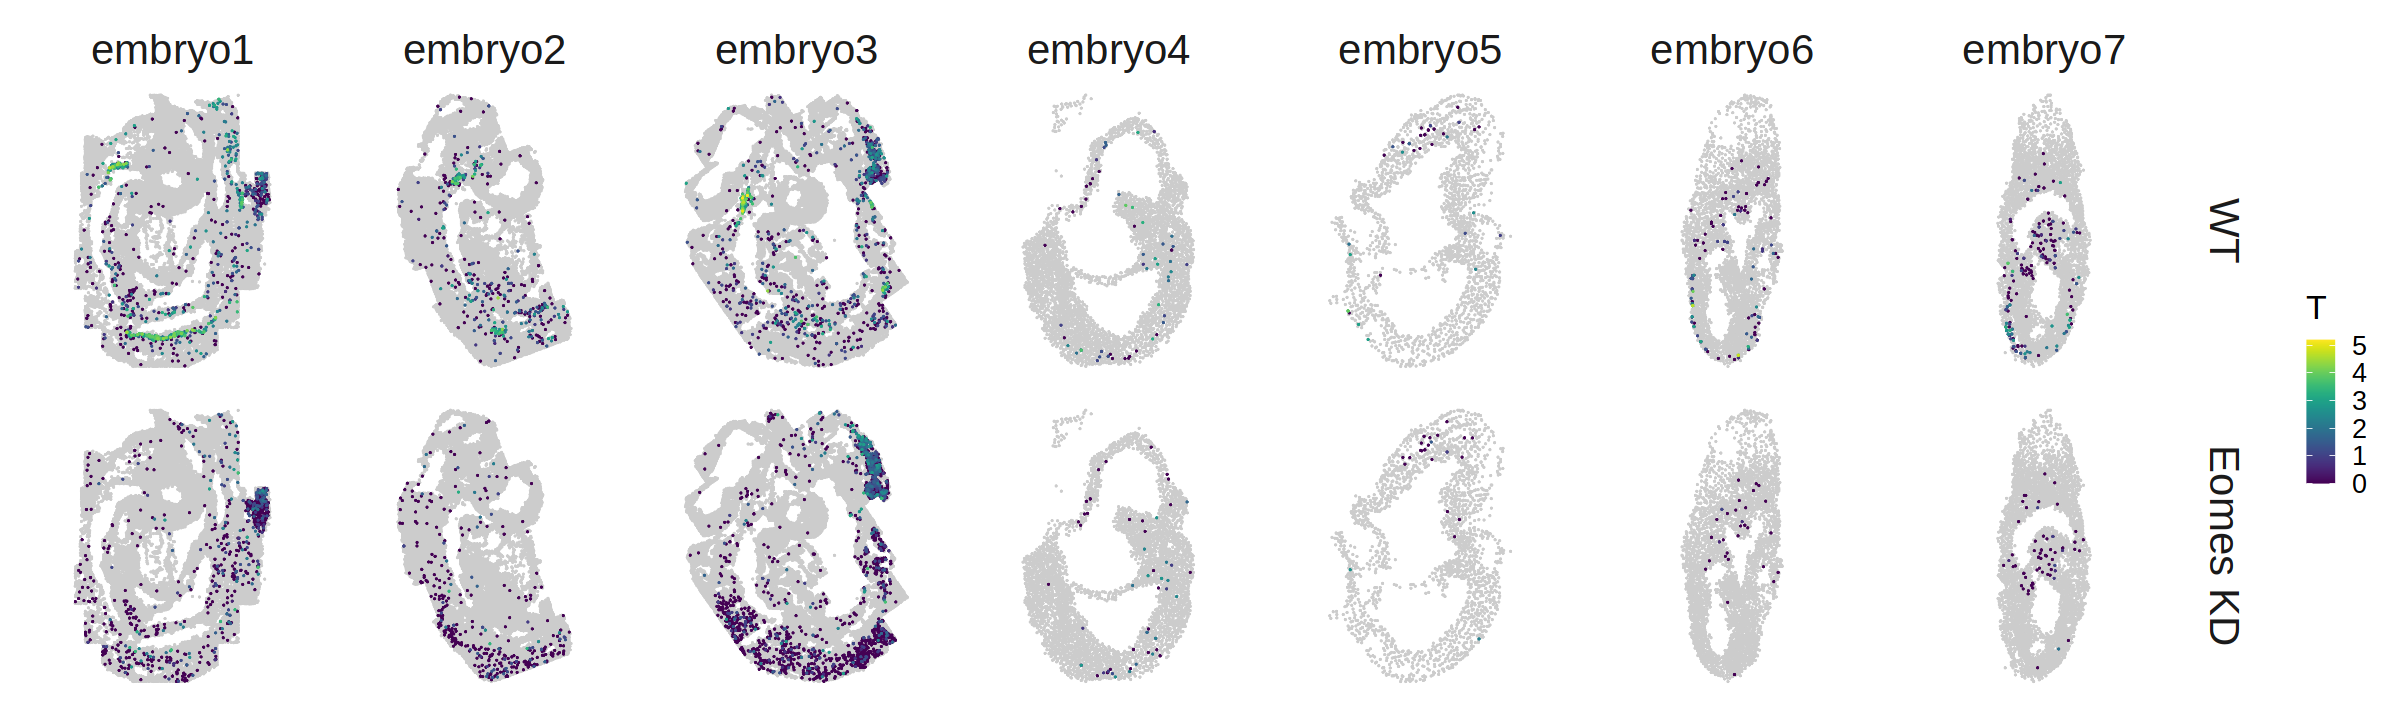

In [93]:
plot_gene('T')

In [94]:
# notochord_genes <- c(
#   "Noto", "Chrd",  "Shh", "T", "Fgf8", "Cer1", "Dkk1", "Lefty1", 
#   "Sfrp1", "Sfrp2", "Adamts9", "Gsc", "Eomes", "Foxa2", "Sox17", 
#   "Isl1", "Col2a1", "Krt8", "Krt18", "Foxj1", "Nog", 
#   "Mixl1", "Cxcr4", "Snai1"
# )


notochord_genes <- c( "T", "Fgf8","Chrd", 'Gsc', 'Lefty1')
    
pdf(file.path(args$outdir, "spatial_expression.pdf"), width = 15, height = 6)
invisible(lapply(notochord_genes, function(g) print(plot_gene(g))))
dev.off()

T

Fgf8

Chrd

Gsc

Lefty1



png 
  2

# Differential Accessibility

In [ ]:
archr = loadArchRProject(io$archR.directory)

In [ ]:
addArchRThreads(12)

In [ ]:
archr <- addMotifAnnotations(ArchRProj = archr, motifSet = "cisbp", name = "Motif")


In [ ]:
meta = as.data.table(seurat@meta.data, keep.rownames = 'cell')

archr <- addCellColData(
  ArchRProj = archr,
  data = meta[match(rownames(archr@cellColData), cell)][day == 'D4.5'] %>% .$celltype_manual,         # Vector, factor, or character array (length = number of cells)
  name = "celltype_manual",   # Name of the new column
  cells = meta[match(rownames(archr@cellColData), cell)][day == 'D4.5'] %>% .$cell,   # Cell names corresponding to the values (optional if same order)
  force = TRUE
)

In [ ]:
meta %>% .$celltype_manual %>% unique()

In [ ]:
markerTest <- getMarkerFeatures(
  ArchRProj = archr, 
  useMatrix = "PeakMatrix",
  groupBy = "celltype_manual",
  testMethod = "wilcoxon",
  bias = c("TSSEnrichment", "log10(nFrags)"),
  useGroups = "Notochord 1",
  bgdGroups = "Notochord 2"
)

pv <- plotMarkers(seMarker = markerTest, name = "Notochord 1", cutOff = "FDR <= 0.1 & abs(Log2FC) >= 1", plotAs = "Volcano")
pv

motifsUp <- peakAnnoEnrichment(
    seMarker = markerTest,
    ArchRProj = archr,
    peakAnnotation = "Motif",
    cutOff = "FDR <= 0.1 & Log2FC >= 0.5"
  )

df <- data.frame(TF = rownames(motifsUp), mlog10Padj = assay(motifsUp)[,1])
df <- df[order(df$mlog10Padj, decreasing = TRUE),]
df$rank <- seq_len(nrow(df))
options(repr.plot.width = 10, repr.plot.height = 5)
ggUp <- ggplot(df, aes(rank, mlog10Padj, color = mlog10Padj)) + 
  geom_point(size = 1) +
  ggrepel::geom_label_repel(
        data = df[rev(seq_len(15)), ], aes(x = rank, y = mlog10Padj, label = TF), 
        size = 5,
        nudge_x = 300,
        nudge_y = 20,
        color = "black",
        max.overlaps = Inf
  ) + theme_ArchR() + 
  ylab("-log10(P-adj) Motif Enrichment") + 
  xlab("Rank Sorted TFs Enriched") +
  scale_color_gradientn(colors = paletteContinuous(set = "comet")) + 
  ggtitle('Noto 1 vs 2 - Up')

ggUp

motifsUp <- peakAnnoEnrichment(
    seMarker = markerTest,
    ArchRProj = archr,
    peakAnnotation = "Motif",
    cutOff = "FDR <= 0.1 & Log2FC <= 0.5"
  )

df <- data.frame(TF = rownames(motifsUp), mlog10Padj = assay(motifsUp)[,1])
df <- df[order(df$mlog10Padj, decreasing = TRUE),]
df$rank <- seq_len(nrow(df))
options(repr.plot.width = 10, repr.plot.height = 5)
ggUp <- ggplot(df, aes(rank, mlog10Padj, color = mlog10Padj)) + 
  geom_point(size = 1) +
  ggrepel::geom_label_repel(
        data = df[rev(seq_len(15)), ], aes(x = rank, y = mlog10Padj, label = TF), 
        size = 5,
        nudge_x = 300,
        nudge_y = 20,
        color = "black",
        max.overlaps = Inf
  ) + theme_ArchR() + 
  ylab("-log10(P-adj) Motif Enrichment") + 
  xlab("Rank Sorted TFs Enriched") +
  scale_color_gradientn(colors = paletteContinuous(set = "comet")) + 
  ggtitle('Noto 1 vs 2 - Down')

ggUp

In [ ]:
markerTest <- getMarkerFeatures(
  ArchRProj = archr, 
  useMatrix = "PeakMatrix",
  groupBy = "celltype_manual",
  testMethod = "wilcoxon",
  bias = c("TSSEnrichment", "log10(nFrags)"),
  useGroups = "DE/Gut",
  bgdGroups = "Notochord 1"
)

pv <- plotMarkers(seMarker = markerTest, name = "DE/Gut", cutOff = "FDR <= 0.1 & abs(Log2FC) >= 1", plotAs = "Volcano")
pv

motifsUp <- peakAnnoEnrichment(
    seMarker = markerTest,
    ArchRProj = archr,
    peakAnnotation = "Motif",
    cutOff = "FDR <= 0.1 & Log2FC >= 0.5"
  )

df <- data.frame(TF = rownames(motifsUp), mlog10Padj = assay(motifsUp)[,1])
df <- df[order(df$mlog10Padj, decreasing = TRUE),]
df$rank <- seq_len(nrow(df))
options(repr.plot.width = 10, repr.plot.height = 5)
ggUp <- ggplot(df, aes(rank, mlog10Padj, color = mlog10Padj)) + 
  geom_point(size = 1) +
  ggrepel::geom_label_repel(
        data = df[rev(seq_len(15)), ], aes(x = rank, y = mlog10Padj, label = TF), 
        size = 5,
        nudge_x = 300,
        nudge_y = 20,
        color = "black",
        max.overlaps = Inf
  ) + theme_ArchR() + 
  ylab("-log10(P-adj) Motif Enrichment") + 
  xlab("Rank Sorted TFs Enriched") +
  scale_color_gradientn(colors = paletteContinuous(set = "comet")) + 
  ggtitle('DE/Gut vs Noto 1 - Up')

ggUp

motifsUp <- peakAnnoEnrichment(
    seMarker = markerTest,
    ArchRProj = archr,
    peakAnnotation = "Motif",
    cutOff = "FDR <= 0.1 & Log2FC <= 0.5"
  )

df <- data.frame(TF = rownames(motifsUp), mlog10Padj = assay(motifsUp)[,1])
df <- df[order(df$mlog10Padj, decreasing = TRUE),]
df$rank <- seq_len(nrow(df))
options(repr.plot.width = 10, repr.plot.height = 5)
ggUp <- ggplot(df, aes(rank, mlog10Padj, color = mlog10Padj)) + 
  geom_point(size = 1) +
  ggrepel::geom_label_repel(
        data = df[rev(seq_len(15)), ], aes(x = rank, y = mlog10Padj, label = TF), 
        size = 5,
        nudge_x = 300,
        nudge_y = 20,
        color = "black",
        max.overlaps = Inf
  ) + theme_ArchR() + 
  ylab("-log10(P-adj) Motif Enrichment") + 
  xlab("Rank Sorted TFs Enriched") +
  scale_color_gradientn(colors = paletteContinuous(set = "comet")) + 
  ggtitle('DE/Gut vs Noto 1 - Down')

ggUp

In [ ]:
markerTest <- getMarkerFeatures(
  ArchRProj = archr, 
  useMatrix = "PeakMatrix",
  groupBy = "celltype_manual",
  testMethod = "wilcoxon",
  bias = c("TSSEnrichment", "log10(nFrags)"),
  useGroups = "DE/Gut",
  bgdGroups = "Notochord 2"
)

pv <- plotMarkers(seMarker = markerTest, name = "DE/Gut", cutOff = "FDR <= 0.1 & abs(Log2FC) >= 1", plotAs = "Volcano")
pv

motifsUp <- peakAnnoEnrichment(
    seMarker = markerTest,
    ArchRProj = archr,
    peakAnnotation = "Motif",
    cutOff = "FDR <= 0.1 & Log2FC >= 0.5"
  )

df <- data.frame(TF = rownames(motifsUp), mlog10Padj = assay(motifsUp)[,1])
df <- df[order(df$mlog10Padj, decreasing = TRUE),]
df$rank <- seq_len(nrow(df))
options(repr.plot.width = 10, repr.plot.height = 5)
ggUp <- ggplot(df, aes(rank, mlog10Padj, color = mlog10Padj)) + 
  geom_point(size = 1) +
  ggrepel::geom_label_repel(
        data = df[rev(seq_len(15)), ], aes(x = rank, y = mlog10Padj, label = TF), 
        size = 5,
        nudge_x = 300,
        nudge_y = 20,
        color = "black",
        max.overlaps = Inf
  ) + theme_ArchR() + 
  ylab("-log10(P-adj) Motif Enrichment") + 
  xlab("Rank Sorted TFs Enriched") +
  scale_color_gradientn(colors = paletteContinuous(set = "comet")) + 
  ggtitle('DE/Gut vs Noto 2 - Up')

ggUp

motifsUp <- peakAnnoEnrichment(
    seMarker = markerTest,
    ArchRProj = archr,
    peakAnnotation = "Motif",
    cutOff = "FDR <= 0.1 & Log2FC <= 0.5"
  )

df <- data.frame(TF = rownames(motifsUp), mlog10Padj = assay(motifsUp)[,1])
df <- df[order(df$mlog10Padj, decreasing = TRUE),]
df$rank <- seq_len(nrow(df))
options(repr.plot.width = 10, repr.plot.height = 5)
ggUp <- ggplot(df, aes(rank, mlog10Padj, color = mlog10Padj)) + 
  geom_point(size = 1) +
  ggrepel::geom_label_repel(
        data = df[rev(seq_len(15)), ], aes(x = rank, y = mlog10Padj, label = TF), 
        size = 5,
        nudge_x = 300,
        nudge_y = 20,
        color = "black",
        max.overlaps = Inf
  ) + theme_ArchR() + 
  ylab("-log10(P-adj) Motif Enrichment") + 
  xlab("Rank Sorted TFs Enriched") +
  scale_color_gradientn(colors = paletteContinuous(set = "comet")) + 
  ggtitle('DE/Gut vs Noto 2 - Down')

ggUp